# 17_2 · Modelo S con ponderación histórica de biomasa

Comparación del modelo S original del 17 con el mismo modelo ajustado con la ponderación de biomasa de pyomo-doe, \(\sigma_X=\max(0{,}06,0{,}08|X_{\rm obs}|)\) en g/L. Se conservan el conjunto de entrenamiento LAB004–009, las condiciones iniciales, los perfiles térmicos, los pulsos y las cotas, parámetros fijos y arranques del ajuste S con inhibición por etanol fija. Los dos vectores se evalúan con la misma pareja de gas archivada del S original y con solubilidad variable. LAB016–024 se usan para evaluar la química.

## Ecuaciones y alcance
\[
\mu=\mu_0a_\mu(T)\frac{N}{N+K_N(T)},\qquad
\beta_S=\beta_{S0}a_\beta(T)\frac{S}{S+K_S(T)}\frac{K_{iE}(T)}{E+K_{iE}(T)}.
\]
\[
\dot X=(\mu-k_d)X,\quad \dot N=-\mu X/Y_{X/N},\quad
\dot S=-X[\mu/Y_{X/S}+\beta_S/Y_{E/S}+m(T)S/(S+1)],\quad \dot E=\beta_SX.
\]
Concentraciones en g/L, tiempo en horas; el 1 del factor de mantenimiento es 1 g/L, igual al módulo original. Se anula mu si S está agotado. Nutrición: salto instantáneo de N, muestra previa al salto si coincide.

Chemical parameters are fixed to their original executed values. The variable-solubility specification above replaces the old gas equations.


## Datos y tratamiento de YAN

Se conservan las 64 observaciones de biomasa posteriores a la inicial. El YAN observado de hasta 20 mg N/L se lleva a cero; se excluyen las observaciones estrictamente posteriores a agotamiento + 12 h. Para LAB006 se fija a cero la observación de 122 h y se aplica el corte después de 134 h. Se conserva el YAN inicial y los pulsos instantáneos. Si una muestra coincide con un pulso se toma el estado anterior al salto. Para S se suman G y F simultáneos y se conserva la propagación de las escalas del 17.

In [1]:
from pathlib import Path
from dataclasses import replace
import sys,json
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/wine_fermentation').is_dir())
assert Path(sys.prefix).name.lower()=='fermentation'
sys.path.insert(0,str(ROOT/'src'));sys.dont_write_bytecode=True
from wine_fermentation import model as kin
from wine_fermentation.data import natural_batches
from wine_fermentation.models.historical.calibration import load
from wine_fermentation.comparison import observations,chemical_observations,CHEMICAL_COLUMNS
data,training,profiles=natural_batches(ROOT)
# Correcciones de recuento inicial indicadas por el usuario; originales conservados.
INITIAL_VIABLE_MCELLS_ML={'LAB004':10.75,'LAB005':11.25}
initial_biomass_audit=[];corrected_training=[]
for batch in training:
 if batch.batch in INITIAL_VIABLE_MCELLS_ML:
  count=INITIAL_VIABLE_MCELLS_ML[batch.batch];x0=count*.03
  ids=np.flatnonzero(np.isclose(batch.time,0.));assert len(ids)==1
  obs0={k:v.copy() for k,v in batch.observations.items()};obs0['X'][ids[0]]=x0
  initial_biomass_audit.append(dict(LAB=batch.batch,original_g_L=batch.initials['X'],viables_millones_mL=count,corregido_g_L=x0))
  batch=replace(batch,initials={**batch.initials,'X':x0},observations=obs0)
  mask=data.batch.eq(batch.batch)&np.isclose(data.time_h,0.)
  assert mask.sum()==1
  data.loc[mask,'X_viable_kg_m3']=x0;data.loc[mask,'X_viable_mcells_ml']=count
  assert batch.initials['X']==batch.observations['X'][ids[0]]
 corrected_training.append(batch)
training=corrected_training
assert len(initial_biomass_audit)==2
display(pd.DataFrame(initial_biomass_audit))

start=kin.normalize_parameters(json.loads((ROOT/'configs/theta/theta_full.json').read_text()))
config=json.loads((ROOT/'configs/models/without_transporters/calibration.json').read_text())
# Tabla 2 de Zenteno: Kn=0.01 g/L a23C; nuestro Kn0 se referencia a20C.
KN_ZENTENO_G_L=0.01;KN_PAPER_REF_K=296.15;KN_CODE_REF_K=293.15
KN_THERMAL_FACTOR=np.exp(kin.FIXED_CONSTANTS['EaKn']*(KN_PAPER_REF_K-KN_CODE_REF_K)/(KN_CODE_REF_K*kin.FIXED_CONSTANTS['R']*KN_PAPER_REF_K))
start['Kn0']=KN_ZENTENO_G_L/KN_THERMAL_FACTOR
KD0_ZENTENO_H=0.00044
start['Kd0']=KD0_ZENTENO_H
assert np.isclose(start['Kn0']*KN_THERMAL_FACTOR,KN_ZENTENO_G_L,rtol=1e-14)
display(pd.Series(dict(Kn_Zenteno_g_L=KN_ZENTENO_G_L,referencia_paper_C=23,Kn0_codigo_g_L=start['Kn0'],referencia_codigo_C=20),name='Kn fijo y conversión de referencia térmica'))
names=[k for k in config['bounds'] if k not in ['aN','KNa','Kn0','Kd0']]
assert len(names)==8 and 'Kn0' not in names and 'Kd0' not in names
bounds={k:config['bounds'][k] for k in names};lo,hi=np.array(list(bounds.values())).T
fixed={k:v for k,v in start.items() if k not in names}
display(pd.Series(fixed,name='Fijos: theta_full salvo Kn y Kd0 de Zenteno'))
display(pd.DataFrame([dict(parametro=k,inicio=start[k],inicio_factible=np.clip(start[k],lo[i]+1e-10,hi[i]-1e-10),minimo=lo[i],maximo=hi[i]) for i,k in enumerate(names)]))


diffs=[]
bylab={b.batch:b for b in training}
for a,b in [('LAB004','LAB005'),('LAB007','LAB008')]:
 aa=pd.Series(bylab[a].observations['X'],index=bylab[a].time);bb=pd.Series(bylab[b].observations['X'],index=bylab[b].time)
 z=pd.concat([aa,bb],axis=1).dropna();diffs.extend((z.iloc[:,0]-z.iloc[:,1]).tolist())
sigma_rep=float(np.sqrt(np.mean(np.square(diffs)))/np.sqrt(2));SIGMA_X=max(.5,3*sigma_rep)
assert len(diffs)>0
print('Pares de réplicas:',len(diffs),'sigma réplica:',sigma_rep,'sigmaX de referencia:',SIGMA_X)
treated=[];audit=[];rules=[]
for b in training:
 obs={k:v.copy() for k,v in b.observations.items()};old=obs['N'].copy()
 obs['N'][np.isfinite(old)&(old<=.020)]=0
 if b.batch=='LAB006':
  ids=np.flatnonzero(np.isclose(b.time,122)&np.isfinite(old));assert len(ids)==1 and np.isclose(old[ids[0]],.027)
  obs['N'][ids]=0;depletion=122.
 else:
  last=max(t for t,d in b.pulses['N']);ids=np.flatnonzero((b.time>=last)&np.isfinite(obs['N'])&(obs['N']==0));assert len(ids)
  depletion=float(b.time[ids[0]])
 obs['N'][b.time>depletion+12]=np.nan
 for i in np.flatnonzero(np.isfinite(old)):
  audit.append(dict(LAB=b.batch,t_h=b.time[i],original_mg=old[i]*1000,usado_mg=obs['N'][i]*1000,estado='Inicial' if b.time[i]==0 else ('Excluido' if not np.isfinite(obs['N'][i]) else ('Transformado' if old[i]!=obs['N'][i] else 'Usado'))))
 assert all(np.array_equal(obs[k],b.observations[k],equal_nan=True) for k in obs if k!='N')
 treated.append(replace(b,observations=obs))
 rules.append(dict(LAB=b.batch,agotamiento_h=depletion,corte_YAN_h=depletion+12,N0_mg=b.initials['N']*1000,pulsos=b.pulses['N'],**{k:int(np.count_nonzero(np.isfinite(obs[k])&(b.time>0))) for k in obs}))
audit=pd.DataFrame(audit);display(pd.DataFrame(rules));display(audit)
def sigma(state,y):
 return np.maximum(.06,.08*np.abs(y)) if state=='X' else kin.sigma_for_state(state,y)
theta={'mu0': 0.09403147367985473, 'betaG0': 0.42243676903335664, 'betaF0': 0.6236552480900203, 'Kn0': 0.008257860224319971, 'Kg0': 4.400775419123265, 'Kf0': 19.296083508118652, 'Kig0': 65.01993873457147, 'Kie0': 96.26516563486751, 'Kd0': 0.00044, 'Yxn': 6.456225797038313, 'Yxg': 0.9660935553477866, 'Yxf': 1.1098958529485594, 'Yeg': 0.4684585383875136, 'Yef': 0.5113278649826252, 'm0': 0.0183385793928771}
assert theta['Kn0']==start['Kn0'] and theta['Kd0']==KD0_ZENTENO_H
assert all(theta[k]==v for k,v in fixed.items())
print('PARÁMETROS QUÍMICOS COMPLETOS',json.dumps(theta,indent=2))


v=load(ROOT);LABS=['LAB019','LAB020','LAB021','LAB016','LAB017','LAB018'];TRAIN=LABS[:3];HOLD=LABS[3:]
raw=pd.read_csv(ROOT/'data/processed/co2_mass_balance_lab016_021_g_l_h.csv',usecols=['lab','time_h','record_kind','remaining_volume_L','co2_raw_g_l_h']);obs=observations(raw)
batches={};volumes={};entry=[]
for lab in LABS:
 b=v.batches[lab];ev=raw.loc[raw.lab.eq(lab)&raw.record_kind.eq('withdrawal_after')].sort_values('time_h');et=ev.time_h.to_numpy();vv=ev.remaining_volume_L.to_numpy()
 def volume(t,et=et,vv=vv):return np.r_[2.,vv][np.searchsorted(et,np.asarray(t),side='right')]
 volumes[lab]=volume
 if lab in TRAIN:b=replace(b,pulses={**b.pulses,'N':tuple((t,d*2/float(volume(t))) for t,d in b.pulses['N'])})
 if lab=='LAB017':b=replace(b,pulses={**b.pulses,'N':((min(t for t,d in b.pulses['N']),sum(d for t,d in b.pulses['N'])),)})
 if lab=='LAB021':b=replace(b,initials={**b.initials,'X':9.*.03})
 batches[lab]=b
 entry.append(dict(LAB=lab,**b.initials,pulsos=b.pulses['N'],corte_h=v.horizons[lab]))
 obs[lab]=obs[lab].loc[obs[lab].time_h.between(0,v.horizons[lab])].copy()
display(pd.DataFrame(entry))

PCO2_BAR=1.0
ETHANOL_G_L_PER_VOL_PERCENT=7.8924
GAS_BOUNDS={'kLa':(0.001,20.),'gain':(.05,3.)}

def saturation(T,E,S):
 a=np.maximum(E,0)/ETHANOL_G_L_PER_VOL_PERCENT
 return 3.295*np.exp((7e-5*a-.02905)*np.asarray(T)-.0179*a-.00111*np.maximum(S,0))*PCO2_BAR

def configure_gas(frames,single=True):
 global gas_equilibrium
 gas_equilibrium={}
 for lab,f in frames.items():
  times=caches[lab][0]
  assert single
  ff=plotframe_s(f)
  T=np.array([kin.temperature_at(batches[lab],float(t)) for t in times])
  E=np.interp(times,ff.index,ff.E)
  S=np.interp(times,ff.index,ff.S)
  gas_equilibrium[lab]=(T,E,S,saturation(T,E,S))

def gas(lab,k,gain=1,activated=True,substeps=1):
 t,source=caches[lab]
 source=source*activation[lab] if activated else source.copy()
 T,E,S,sat=gas_equilibrium[lab]
 cd=np.zeros(len(t));qout=np.zeros(len(t));acc=np.zeros(len(t))
 qout[0]=max(source[0]-k*sat[0],0.)
 for i,dt in enumerate(np.diff(t),1):
  qp=(source[i-1]+source[i])/2;previous=cd[i-1];current=previous
  for j in range(substeps):
   h=dt/substeps;fraction=(j+.5)/substeps;cs=sat[i-1]*(1-fraction)+sat[i]*fraction
   if current>cs:
    current=cs+(current-cs)*np.exp(-k*h)
   else:
    D=cs-current
    if qp<=0 or D<=0:delta=0.
    elif k*D<=qp:delta=D*(-np.expm1(-k*h))
    else:
     crossing=(D-qp/k)/qp;linear=min(h,crossing);delta=qp*linear
     if crossing<h:delta+=(qp/k)*(-np.expm1(-k*(h-crossing)))
    current+=delta
  cd[i]=current;acc[i]=(current-previous)/dt;qout[i]=qp-acc[i]
 assert cd.min()>=-1e-12 and qout.min()>-1e-10
 assert np.max(abs(np.diff(cd)-np.diff(t)*((source[:-1]+source[1:])/2-qout[1:])))<1e-10
 return pd.DataFrame(dict(qprod=source,Cd=cd,Csat=sat,T=T,E=E,S=S,qgas=qout,qpred=gain*qout),index=t)



Pares de réplicas: 23 sigma réplica: 0.1189341469231937 sigmaX de referencia: 0.5
PARÁMETROS QUÍMICOS COMPLETOS {
  "mu0": 0.09403147367985473,
  "betaG0": 0.42243676903335664,
  "betaF0": 0.6236552480900203,
  "Kn0": 0.008257860224319971,
  "Kg0": 4.400775419123265,
  "Kf0": 19.296083508118652,
  "Kig0": 65.01993873457147,
  "Kie0": 96.26516563486751,
  "Kd0": 0.00044,
  "Yxn": 6.456225797038313,
  "Yxg": 0.9660935553477866,
  "Yxf": 1.1098958529485594,
  "Yeg": 0.4684585383875136,
  "Yef": 0.5113278649826252,
  "m0": 0.0183385793928771
}


,LAB,original_g_L,viables_millones_mL,corregido_g_L
0,LAB004,0.3939,10.75,0.3225
1,LAB005,0.4932,11.25,0.3375


Kn_Zenteno_g_L          0.010000
referencia_paper_C     23.000000
Kn0_codigo_g_L          0.008258
referencia_codigo_C    20.000000
Name: Kn fijo y conversión de referencia térmica, dtype: float64

Kn0     0.008258
Kg0     4.400775
Kf0    19.296084
Kd0     0.000440
Yxg     0.966094
Yxf     1.109896
m0      0.018339
Name: Fijos: theta_full salvo Kn y Kd0 de Zenteno, dtype: float64

,parametro,inicio,inicio_factible,minimo,maximo
0,mu0,0.078728,0.078728,0.05,1.0000
1,betaG0,0.428878,0.428878,0.10,10.0000
2,betaF0,3.440399,3.440399,0.10,10.0000
3,Kig0,17.845213,17.845213,5.00,1000.0000
4,Kie0,24.895476,24.895476,5.00,1000.0000
5,Yxn,3.734653,3.734653,1.00,100.0000
6,Yeg,0.250395,0.250395,0.10,0.5114
7,Yef,0.684927,0.511400,0.10,0.5114


,LAB,agotamiento_h,corte_YAN_h,N0_mg,pulsos,X,N,G,F,E
0,LAB004,91.0,103.0,230.76,"((68.5, 0.08),)",10,8,12,12,4
1,LAB005,91.0,103.0,227.30,"((68.5, 0.08),)",10,8,12,12,4
2,LAB006,122.0,134.0,229.12,"((100.0, 0.08),)",12,9,14,14,4
3,LAB007,88.0,100.0,239.04,"((65.5, 0.08),)",11,8,12,12,5
4,LAB008,88.0,100.0,239.22,"((65.5, 0.08),)",11,8,12,12,5
5,LAB009,64.0,76.0,237.40,"((41.84615384615385, 0.08),)",10,6,11,11,4


,LAB,t_h,original_mg,usado_mg,estado
0,LAB004,0.0,230.76,230.76,Inicial
1,LAB004,19.0,182.72,182.72,Usado
2,LAB004,26.0,157.42,157.42,Usado
3,LAB004,43.0,60.16,60.16,Usado
4,LAB004,50.0,19.00,0.00,Transformado
...,...,...,...,...,...
74,LAB009,88.0,17.00,NaN,Excluido
75,LAB009,96.0,19.00,NaN,Excluido
76,LAB009,120.0,5.00,NaN,Excluido
77,LAB009,144.0,25.00,NaN,Excluido


,LAB,X,N,G,F,E,pulsos,corte_h
0,LAB019,0.283162,0.230025,79.190000,78.970000,12.075372,"((64.33333333333277, 0.08648648648648648),)",166.000000
1,LAB020,0.153342,0.225556,77.940000,79.520000,11.917524,"((71.66666666666694, 0.08888888888888889),)",172.333333
2,LAB021,0.270000,0.231202,80.190000,81.040000,11.759676,"((47.5, 0.08648648648648648),)",166.000000
3,LAB016,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93555555555583, 0.14),)",151.100000
4,LAB017,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.933611111110835, 0.28),)",141.000000
5,LAB018,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93166666666694, 0.14),)",141.000000


## Recalibración química · LAB004–009

In [2]:
YXS=1/(1/theta['Yxg']+1/theta['Yxf']);STATES=['X','N','S','E']
PARAMS=['mu0','betaS0','Ks0','Kie0','Yxn','Yes']
LOW=np.array([.05,.1,.1,5.,1.,.1]);HIGH=np.array([1.,20.,200.,1000.,100.,.5114])
def terms_s(t,y,p,b):
 x,n,s,e=np.maximum(y,0);tk=kin.temperature_at(b,t)+273.15;R=kin.FIXED_CONSTANTS['R']
 ak=np.exp(46055*(tk-293.15)/(293.15*R*tk))
 mu=p['mu0']*np.exp(59453*(tk-300)/(300*R*tk))*n/(n+theta['Kn0']*ak+1e-8) if s>0 else 0.
 beta=p['betaS0']*np.exp(11000*(tk-296.15)/(296.15*R*tk))*s/(s+p['Ks0']*ak+1e-8)*(p['Kie0']*(ak+1e-8)/(e+p['Kie0']*(ak+1e-8)))
 td=-.0001*e**3+.0049*e**2-.1279*e+315.89
 kd=theta['Kd0']*np.exp(.0415*e+130000*(tk-305.65)/(305.65*R*tk)) if tk>=td else 0.
 maint=theta['m0']*np.exp(37681*(tk-293.3)/(293.3*R*tk))*s/(s+kin.MAINTENANCE_SUGAR_CUTOFF_KG_M3)
 return mu,beta,kd,maint

def simulate_s(b,p):
 def rhs(t,y):
  x=max(y[0],0);mu,be,kd,m=terms_s(t,y,p,b)
  return [(mu-kd)*x,-mu*x/p['Yxn'],-(mu/YXS+be/p['Yes']+m)*x,be*x]
 tt=np.asarray(b.time);y=np.array([b.initials['X'],b.initials['N'],b.initials['G']+b.initials['F'],b.initials['E']]);now=tt[0];rec={now:y.copy()};events={};jumps=[];minimum=y.copy()
 for t,d in b.pulses.get('N',()):
  assert t>now and d>=0
  if t<=tt[-1]:events[t]=events.get(t,0)+d
 for end in sorted(set([float(tt[-1])]+list(events))):
  requested=np.unique(np.r_[tt[(tt>now)&(tt<=end)],end])
  sol=solve_ivp(rhs,(now,end),y,t_eval=requested,method='LSODA',rtol=2e-6,atol=2e-8,max_step=.5)
  if not sol.success or not np.isfinite(sol.y).all() or np.any(sol.y.min(axis=1)<-np.array([1e-6,1e-6,1e-4,1e-6])):raise RuntimeError('Integración inválida '+b.batch)
  minimum=np.minimum(minimum,sol.y.min(axis=1));rec.update({float(t):z.copy() for t,z in zip(sol.t,sol.y.T)})
  y=sol.y[:,-1].copy();now=end
  if end in events:
   before=y.copy();y[1]+=events[end];jumps.append((end,before,y.copy()))
 f=pd.DataFrame(np.maximum([rec[float(t)] for t in tt],0),index=tt,columns=STATES)
 f.attrs['jumps']=jumps;f.attrs['minima']=minimum;return f

def plotframe_s(f):
 rows=[];times=[]
 for t,before,after in f.attrs['jumps']:
  rows.extend([before,after]);times.extend([t,t])
 return pd.concat([f,pd.DataFrame(rows,index=times,columns=STATES)]).sort_index(kind='stable') if rows else f

def targets(b,s):
 y=b.observations[s] if s!='S' else b.observations['G']+b.observations['F']
 sig=sigma(s,y) if s!='S' else np.hypot(kin.sigma_for_state('G',b.observations['G']),kin.sigma_for_state('F',b.observations['F']))
 return y,sig,np.isfinite(y)&(b.time>0)
support_s=[(b,s,*targets(b,s)) for b in treated for s in STATES]
NR_S=sum(mask.sum() for b,s,y,sg,mask in support_s);rejections=0
print('Soporte de ajuste');display(pd.DataFrame([dict(LAB=b.batch,estado=s,n=int(mask.sum())) for b,s,y,sg,mask in support_s]))
def residual_s(logp):
 global rejections
 p=dict(zip(PARAMS,np.exp(logp)))
 try:
  predictions={b.batch:simulate_s(b,p) for b in treated}
  return np.concatenate([(predictions[b.batch][s].to_numpy()[mask]-y[mask])/sg[mask] for b,s,y,sg,mask in support_s])
 except RuntimeError:
  rejections+=1;return np.full(NR_S,1e5)
ps_free={'mu0':0.08934685518404714,'betaS0':0.7790518060881909,'Ks0':51.79327570452845,'Kie0':999.9894538748339,'Yxn':6.193688479843567,'Yes':0.4893196389269888}
FREE_PARAMS=[k for k in PARAMS if k!='Kie0'];SELECT=[PARAMS.index(k) for k in FREE_PARAMS];KIE_FIXED=theta['Kie0']
LOW_FREE=LOW[SELECT];HIGH_FREE=HIGH[SELECT]
def expand_fixed(logp):
 p=dict(zip(FREE_PARAMS,np.exp(logp)));p['Kie0']=KIE_FIXED
 return np.log([p[k] for k in PARAMS])
def residual_fixed(logp):return residual_s(expand_fixed(logp))
ps_original={'mu0': 0.09085058816701197, 'betaS0': 0.8189664538991809, 'Ks0': 23.046564567082594, 'Kie0': 96.26516563486751, 'Yxn': 6.497331613020979, 'Yes': 0.4893180893478443}
assert ps_original['Kie0'] == KIE_FIXED
counts = {s: sum(int(mask.sum()) for _, state, _, _, mask in support_s if s == state) for s in STATES}
assert counts['X'] == 64 and counts['N'] == 47
lab006 = next(b for b in treated if b.batch == 'LAB006')
assert lab006.observations['N'][lab006.time == 122].item() == 0.
assert np.isnan(lab006.observations['N'][lab006.time > 134]).all()
assert all(len(b.pulses['N']) == 1 and b.pulses['N'][0][1] == .08 for b in treated)
fits=[]
for i,mult in enumerate([np.ones(5),np.array([1.1,1.2,.5,.9,1.])]):
 seed=np.clip(np.array([ps_free[k] for k in FREE_PARAMS])*mult,LOW_FREE*1.00001,HIGH_FREE*.99999)
 result=least_squares(residual_fixed,np.log(seed),bounds=(np.log(LOW_FREE),np.log(HIGH_FREE)),diff_step=1e-3,max_nfev=180,ftol=1e-6,xtol=1e-6,gtol=1e-5)
 fits.append(result);print('Inicio Kie fijo',i,'MSE',np.mean(result.fun**2),'nfev',result.nfev,'convergencia',result.success,result.message,flush=True)
fit=min(fits,key=lambda r:np.sum(r.fun**2));ps=dict(zip(PARAMS,np.exp(expand_fixed(fit.x))))
ps['Kie0']=KIE_FIXED

assert ps['Kie0'] == KIE_FIXED
assert np.all(np.exp(fit.x) >= LOW_FREE) and np.all(np.exp(fit.x) <= HIGH_FREE)
display(pd.DataFrame({"S 17": ps_original, "S 17_2": ps}))
print("PARÁMETROS S 17_2",json.dumps(ps,indent=2))
print("Y_X/N:",ps_original['Yxn'],"→",ps['Yxn'],"; rechazos:",rejections)

calibration_models = {"S 17": ps_original, "S 17_2": ps}
training_curves = {label: {b.batch: simulate_s(b, p) for b in treated}
                   for label, p in calibration_models.items()}


Soporte de ajuste
Inicio Kie fijo 0 MSE 5.45099655878154 nfev 12 convergencia True `xtol` termination condition is satisfied.
Inicio Kie fijo 1 MSE 5.450962213013908 nfev 12 convergencia True `ftol` termination condition is satisfied.
PARÁMETROS S 17_2 {
  "mu0": 0.08518294735912872,
  "betaS0": 0.8990433077446598,
  "Ks0": 18.43978373874834,
  "Kie0": 96.26516563486751,
  "Yxn": 5.31642216832974,
  "Yes": 0.48428251944662287
}
Y_X/N: 6.497331613020979 → 5.31642216832974 ; rechazos: 0


,LAB,estado,n
0,LAB004,X,10
1,LAB004,N,8
2,LAB004,S,12
3,LAB004,E,4
4,LAB005,X,10
5,LAB005,N,8
6,LAB005,S,12
7,LAB005,E,4
8,LAB006,X,12
9,LAB006,N,9


,S 17,S 17_2
mu0,0.090851,0.085183
betaS0,0.818966,0.899043
Ks0,23.046565,18.439784
Kie0,96.265166,96.265166
Yxn,6.497332,5.316422
Yes,0.489318,0.484283


## Evaluación en LAB016–024

Las dos químicas usan la pareja original del modelo S archivada en el 17 y las mismas entradas experimentales. LAB019–021 se usaron históricamente para ajustar esa pareja de gas. En LAB022–024 se evalúa hasta 190 h y se conserva el hueco original del flujo observado. Los rombos en los gráficos de azúcar representan la referencia por densidad, como en el 17.

LAB022–024 usan el mismo perfil térmico de referencia que LAB016–021: mediana por minuto, interpolación de huecos de hasta dos minutos y, por tramo continuo, mediana centrada de 20 minutos seguida de media centrada de 45 minutos. La temperatura filtrada se interpola a la malla del modelo.

In [3]:
HOLDOUT_MODEL = 'S'
HOLDOUT_SINGLE = True
HOLDOUT_GAS_PARAMS = (0.13796553316180868, 0.6586783889606775)

import nbformat
from types import FunctionType
from wine_fermentation.models.historical.calibration import local_to_utc, temperature_signals

instrument = json.loads((ROOT / "configs/co2_instrument.json").read_text(encoding="utf-8"))
prep_path = ROOT / "notebooks/preparing_data/lab022_024_data.source.ipynb"
prep_nb = nbformat.read(prep_path, as_version=4)
sample_code = [cell.source for cell in prep_nb.cells if cell.cell_type == "code" and
               any(marker in cell.source for marker in
                   ("workbook = data_dir /", "y15_sources = {", "oculyze_frames = []"))]
assert len(sample_code) == 3
prepared = {}
for source in sample_code:
    python_source = "\n".join(line for line in source.splitlines() if not line.startswith("%"))
    exec(compile(python_source, str(prep_path), "exec"), prepared)

holdout_labs = prepared["labs"]
holdout_biomass = prepared["oculyze"].assign(X_g_L=lambda f: .03 * f["Viable concentration"])
holdout_chemistry = prepared["chemistry"]
holdout_nutrition = (prepared["nutrition"] - prepared["inoculation"]).dt.total_seconds() / 3600
holdout_horizon = 190.
# Dosis confirmada por lote. Equivalente de YAN de SFX y fracción de N en FDA.
pulse_mass_n_g = 1.0 * .10 + .4 * (2 * 14.007 / 132.1)

reactors = prepared["experiments"]["Fermentador"]
reactor_map = pd.Series(reactors.index, index=reactors)
def read_holdout_backup(filename, *values, hours_before=0.):
    frame = pd.read_csv(prepared["data_dir"] / filename,
                        usecols=["timestamp", "fermentador", *values], parse_dates=["timestamp"])
    frame["lab"] = frame["fermentador"].map(reactor_map)
    frame["h"] = (frame["timestamp"] - frame["lab"].map(prepared["inoculation"])).dt.total_seconds() / 3600
    return frame.loc[frame["h"].ge(-hours_before)].sort_values("h")

holdout_temperature = read_holdout_backup("backup_global_temperatura.csv", "T", "SP", hours_before=6.)
holdout_temperature["timestamp"] = local_to_utc(holdout_temperature["timestamp"])
holdout_temperature_profiles = {}
holdout_raw_flow = read_holdout_backup("backup_global_co2.csv", "flow_sccm")
mass_factor = 44.0095 * 60 * instrument["co2_correction_factor"] / (1000 * 24.16)
holdout_batches, holdout_flow, pulse_rows = {}, {}, []
for lab in holdout_labs:
    samples = prepared["offline"].loc[prepared["offline"]["lab"].eq(lab)]
    withdrawals = samples.loc[samples["Observaciones"].eq("se quitan 50ml"), "hours"].to_numpy()
    initial_volume = float(prepared["experiments"].at[lab, "Volumen_Inicial_L"].removesuffix("L"))
    pulse_h = holdout_nutrition[lab]
    pulse_volume = initial_volume - .05 * np.searchsorted(withdrawals, pulse_h, side="right")
    pulse_n = pulse_mass_n_g / pulse_volume
    start_sample = holdout_biomass.loc[holdout_biomass["lab"].eq(lab) &
                                       holdout_biomass["sample"].eq("01")].iloc[0]
    start = float(start_sample["hours"])
    assert start == .25
    chem = holdout_chemistry.loc[holdout_chemistry["lab"].eq(lab)]
    initial = chem.loc[chem["sample"].eq("01")].iloc[0]
    initials = {"X": start_sample["X_g_L"], "N": initial["YAN for plot"] / 1000,
                "G": initial["GLUCOSE-320"], "F": initial["Fructose (derived)"], "E": 10.010194}
    biomass_h = holdout_biomass.loc[holdout_biomass["lab"].eq(lab), "hours"]
    # Se incluyen las horas de muestreo para evaluar la solución directamente.
    times = np.unique(np.r_[np.arange(start, holdout_horizon, 1/12), holdout_horizon, pulse_h,
                           chem.loc[chem["hours"].ge(start), "hours"], biomass_h])
    temp = holdout_temperature.loc[holdout_temperature["lab"].eq(lab)]
    assert temp.timestamp.is_unique and temp["h"].min() <= start and temp["h"].max() >= holdout_horizon
    t0 = local_to_utc([prepared["inoculation"][lab]])[0]
    profile = temperature_signals(temp, t0)
    holdout_temperature_profiles[lab] = profile
    filtered = profile.dropna(subset=[v.temperature_variant])
    assert filtered.time_h.min() <= start and holdout_horizon - filtered.time_h.max() <= 1/60 + 1e-8
    temp_c = np.interp(times, filtered.time_h, filtered[v.temperature_variant])
    holdout_batches[lab] = kin.BatchData(
        medium="natural", batch=lab, time=times, temperature_c=temp_c,
        pulses={"N": ((pulse_h, pulse_n),)}, observations={}, initials=initials,
    )
    pulse_rows.append({"LAB": lab, "Pulso [h]": pulse_h, "Volumen [L]": pulse_volume,
                       "Aporte [mg N/L]": 1000 * pulse_n})
    raw = holdout_raw_flow.loc[holdout_raw_flow["lab"].eq(lab) &
                               holdout_raw_flow["h"].gt(0)].copy()
    assert raw["h"].max() >= holdout_horizon
    raw["bin"] = np.ceil(raw["h"] / .5 - 1e-10).astype(int)
    sample_volumes = initial_volume - .05 * np.searchsorted(withdrawals, raw["h"], side="right")
    raw["mass_flow"] = raw["flow_sccm"] * mass_factor / sample_volumes
    means = {}
    for index, window in raw.groupby("bin"):
        end = index * .5
        if end > holdout_horizon:
            break
        gaps = np.diff(np.r_[end - .5, window["h"], end])
        valid = len(window) >= 30 and gaps.max() <= 2 / 60 + 1e-10
        means[end] = window["mass_flow"].mean() if valid else np.nan
    holdout_flow[lab] = pd.Series(means).reindex(np.arange(.5, holdout_horizon + .5, .5))
display(pd.DataFrame(pulse_rows).set_index("LAB").round(3))

,Pulso [h],Volumen [L],Aporte [mg N/L]
LAB,,,
LAB022,113.633,1.85,99.906
LAB023,113.783,1.85,99.906
LAB024,113.883,1.85,99.906


In [4]:
def simulate_holdout(batch, ps):
    # Se localiza el agotamiento antes de aplicar la ecuación sin crecimiento.
    sugar_indices = (2,) if HOLDOUT_SINGLE else (2, 3)
    def integrate_to_event(rhs, interval, initial, *, t_eval, **options):
        depleted = [index for index in sugar_indices if initial[index] <= 0]

        def after_depletion(t, state, index):
            state = state.copy()
            state[index] = 0.
            derivative = rhs(t, state)
            derivative[index] = 0.
            return derivative

        if len(depleted):
            return solve_ivp(lambda t, y: after_depletion(t, y, depleted[0]),
                             interval, initial, t_eval=t_eval, **options)

        def depletion_event(index):
            def event(t, state):
                return state[index]
            event.terminal = True
            event.direction = -1
            return event

        def before_depletion(t, state):
            # Las etapas de prueba pueden cruzar cero antes de que el solver localice el evento.
            state = state.copy()
            state[list(sugar_indices)] = np.maximum(state[list(sugar_indices)], np.finfo(float).tiny)
            return rhs(t, state)

        before = solve_ivp(before_depletion, interval, initial, t_eval=t_eval,
                           events=[depletion_event(index) for index in sugar_indices], **options)
        if before.status != 1:
            return before
        [event_index] = [i for i, hits in enumerate(before.t_events) if len(hits)]
        event_time = before.t_events[event_index][0]
        state = before.y_events[event_index][0].copy()
        index = sugar_indices[event_index]
        state[index] = 0.
        remaining = t_eval[t_eval > event_time]
        if not len(remaining):
            return before
        after = solve_ivp(lambda t, y: after_depletion(t, y, index),
                          (event_time, interval[1]), state, t_eval=remaining, **options)
        after.t = np.r_[before.t, after.t]
        before_states = np.asarray(before.y).reshape(len(initial), -1)
        after.y = np.column_stack([before_states, after.y])
        return after

    simulate_context = dict(globals(), solve_ivp=integrate_to_event)
    return FunctionType(simulate_s.__code__, simulate_context)(batch, ps)

def run_holdout(ps):
    holdout_kinetic, holdout_plot, holdout_source, holdout_activation = {}, {}, {}, {}
    for lab, batch in holdout_batches.items():
        trajectory = simulate_holdout(batch, ps)
        frame = plotframe_s(trajectory) if HOLDOUT_SINGLE else with_jumps(trajectory)
        holdout_kinetic[lab], holdout_plot[lab] = trajectory, frame
        if HOLDOUT_SINGLE:
            [(pulse_h, before, after)] = trajectory.attrs["jumps"]
        else:
            [jump] = trajectory.attrs["pulse_jumps"]
            pulse_h, before, after = jump["t"], jump["before"], jump["after"]
        np.testing.assert_allclose([pulse_h, after[1] - before[1]], batch.pulses["N"][0], atol=1e-12)
        times = np.r_[np.arange(batch.time[0], holdout_horizon, .1), holdout_horizon]
        source = []
        variables = ["X", "N", "S", "E"] if HOLDOUT_SINGLE else kin.STATE_NAMES
        for t in times:
            y = [np.interp(t, frame.index, frame[state]) for state in variables]
            if HOLDOUT_SINGLE:
                mu, fermentation, _, _ = terms_s(t, y, ps, batch)
            else:
                rates = kin.kinetic_terms(theta, kin.temperature_at(batch, t), *y)
                mu = rates["mu"] if y[2] > 0 and y[3] > 0 else 0.
                fermentation = rates["beta_g"] + rates["beta_f"]
            source.append((mu / 12.72 + fermentation / 1.05) * y[0])
        sugar = frame["S" if HOLDOUT_SINGLE else "GF"]
        consumed = sugar.iloc[0] - np.interp(times, frame.index, sugar)
        z = np.clip((consumed - 5.) / 5., 0., 1.)
        holdout_activation[lab] = z * z * (3. - 2. * z)
        holdout_source[lab] = (times, np.asarray(source))

    # El integrador de gas usa diccionarios globales. Cada ejecución del holdout recibe los suyos.
    gas_context = dict(globals(), batches=holdout_batches, caches=holdout_source, activation=holdout_activation)
    FunctionType(configure_gas.__code__, gas_context)(holdout_kinetic, HOLDOUT_SINGLE)
    predict_gas = FunctionType(gas.__code__, gas_context, argdefs=gas.__defaults__)
    holdout_gas = {lab: predict_gas(lab, *HOLDOUT_GAS_PARAMS) for lab in holdout_labs}
    holdout_mean_gas = {}
    for lab, curve in holdout_gas.items():
        times = curve.index.to_numpy()
        cumulative = np.r_[0., np.cumsum(np.diff(times) * curve["qpred"].to_numpy()[1:])]
        ends = holdout_flow[lab].index.to_numpy()
        ends = ends[ends - .5 >= times[0]]
        mean = (np.interp(ends, times, cumulative) - np.interp(ends - .5, times, cumulative)) / .5
        holdout_mean_gas[lab] = pd.Series(mean, index=ends)
    return holdout_kinetic, holdout_plot, holdout_gas, holdout_mean_gas

def predict_historical(ps):
    cores = {lab: simulate_s(batch, ps) for lab, batch in batches.items()}
    caches, activation = {}, {}
    for lab, frame in cores.items():
        b = batches[lab]
        f = plotframe_s(frame)
        tt = np.unique(np.r_[np.arange(0, float(f.index[-1]), .1), f.index[-1]])
        production = []
        for t in tt:
            y = [np.interp(t, f.index, f[k]) for k in STATES]
            mu, be, _, _ = terms_s(t, y, ps, b)
            production.append((mu/12.72 + be/1.05)*y[0])
        caches[lab] = tt, np.asarray(production)
        z = np.clip((b.initials['G']+b.initials['F']-np.interp(tt,f.index,f.S)-5)/5,0,1)
        activation[lab] = z*z*(3-2*z)
    context = dict(globals(), caches=caches, activation=activation)
    FunctionType(configure_gas.__code__, context, argdefs=configure_gas.__defaults__)(cores, True)
    predict = FunctionType(gas.__code__, context, argdefs=gas.__defaults__)
    return cores, {lab: predict(lab, *HOLDOUT_GAS_PARAMS) for lab in LABS}

historical = {label: predict_historical(p) for label, p in calibration_models.items()}
recent = {label: run_holdout(p) for label, p in calibration_models.items()}
original_cores, original_gas = historical["S 17"]
reduced_cores, reduced_gas = historical["S 17_2"]
original_train = training_curves["S 17"]
reduced_train = training_curves["S 17_2"]
holdout_kinetic16, holdout_plot16, holdout_gas16, holdout_mean_gas16 = recent["S 17"]
holdout_kinetic, holdout_plot, holdout_gas, holdout_mean_gas = recent["S 17_2"]


         n     sesgo      RMSE
Modelo                        
S 17    64  0.228225  0.422482
S 17_2  64 -0.037336  0.296839
                n     sesgo      RMSE
LAB    Modelo                        
LAB004 S 17    10  0.255199  0.356708
       S 17_2  10 -0.015809  0.228521
LAB005 S 17    10  0.216775  0.246304
       S 17_2  10 -0.050011  0.148901
LAB006 S 17    12 -0.191410  0.489876
       S 17_2  12 -0.405885  0.560214
LAB007 S 17    11  0.374482  0.435457
       S 17_2  11  0.099154  0.159895
LAB008 S 17    11  0.291027  0.404257
       S 17_2  11  0.018683  0.183674
LAB009 S 17    10  0.486299  0.527360
       S 17_2  10  0.184311  0.218390
                 n     sesgo      RMSE
Periodo Modelo                        
Antes   S 17    30  0.012126  0.344480
        S 17_2  30 -0.141748  0.354844
Después S 17    34  0.418901  0.480913
        S 17_2  34  0.054792  0.234008


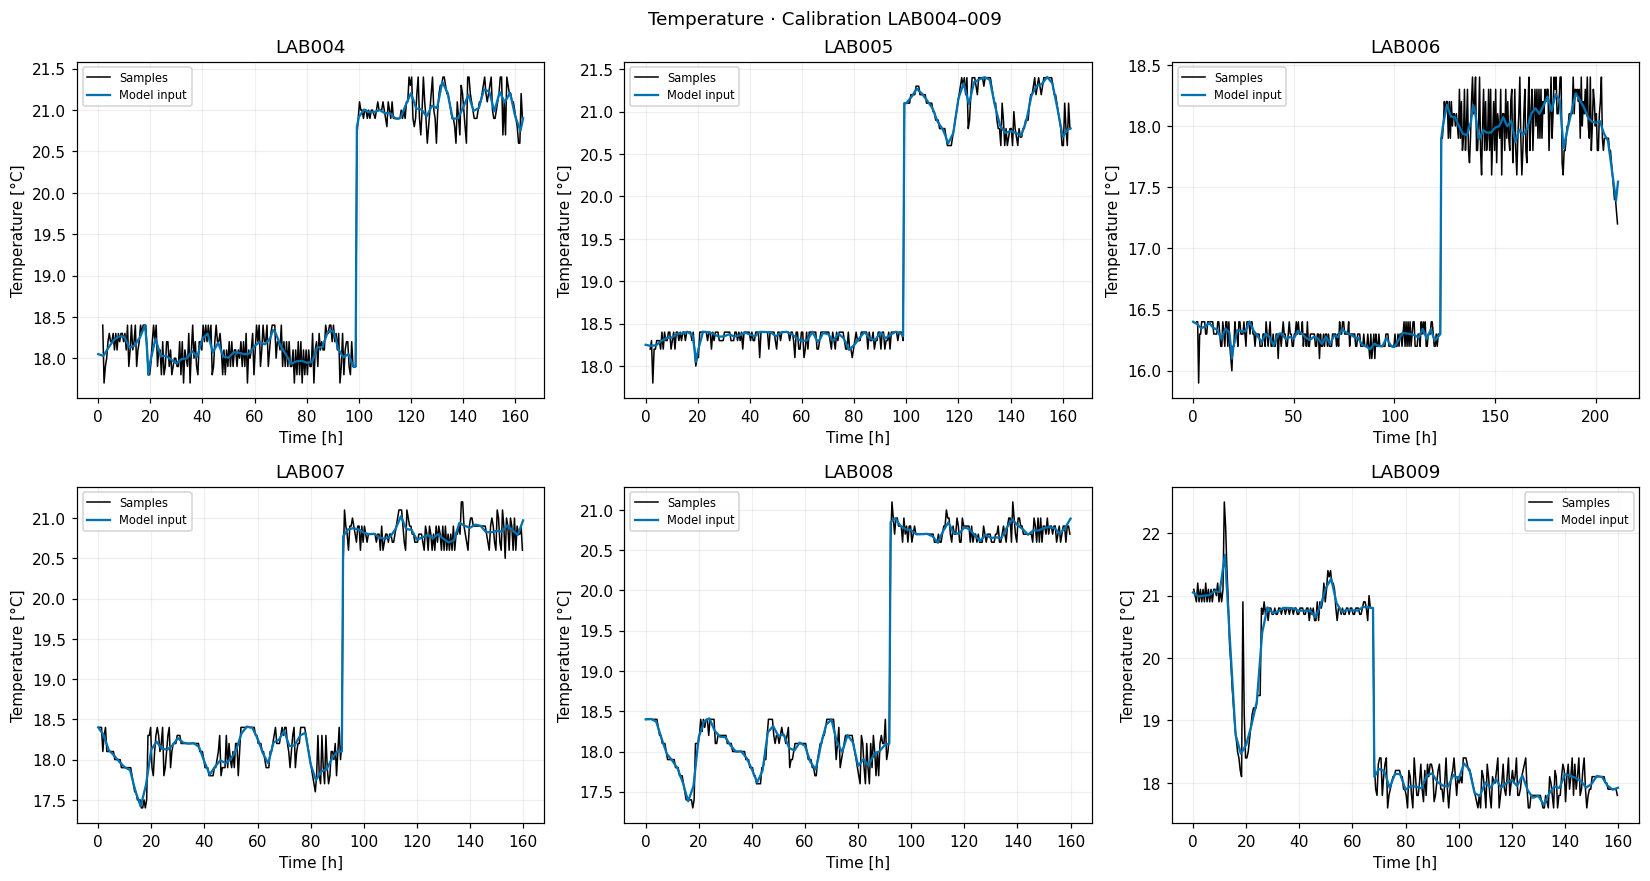

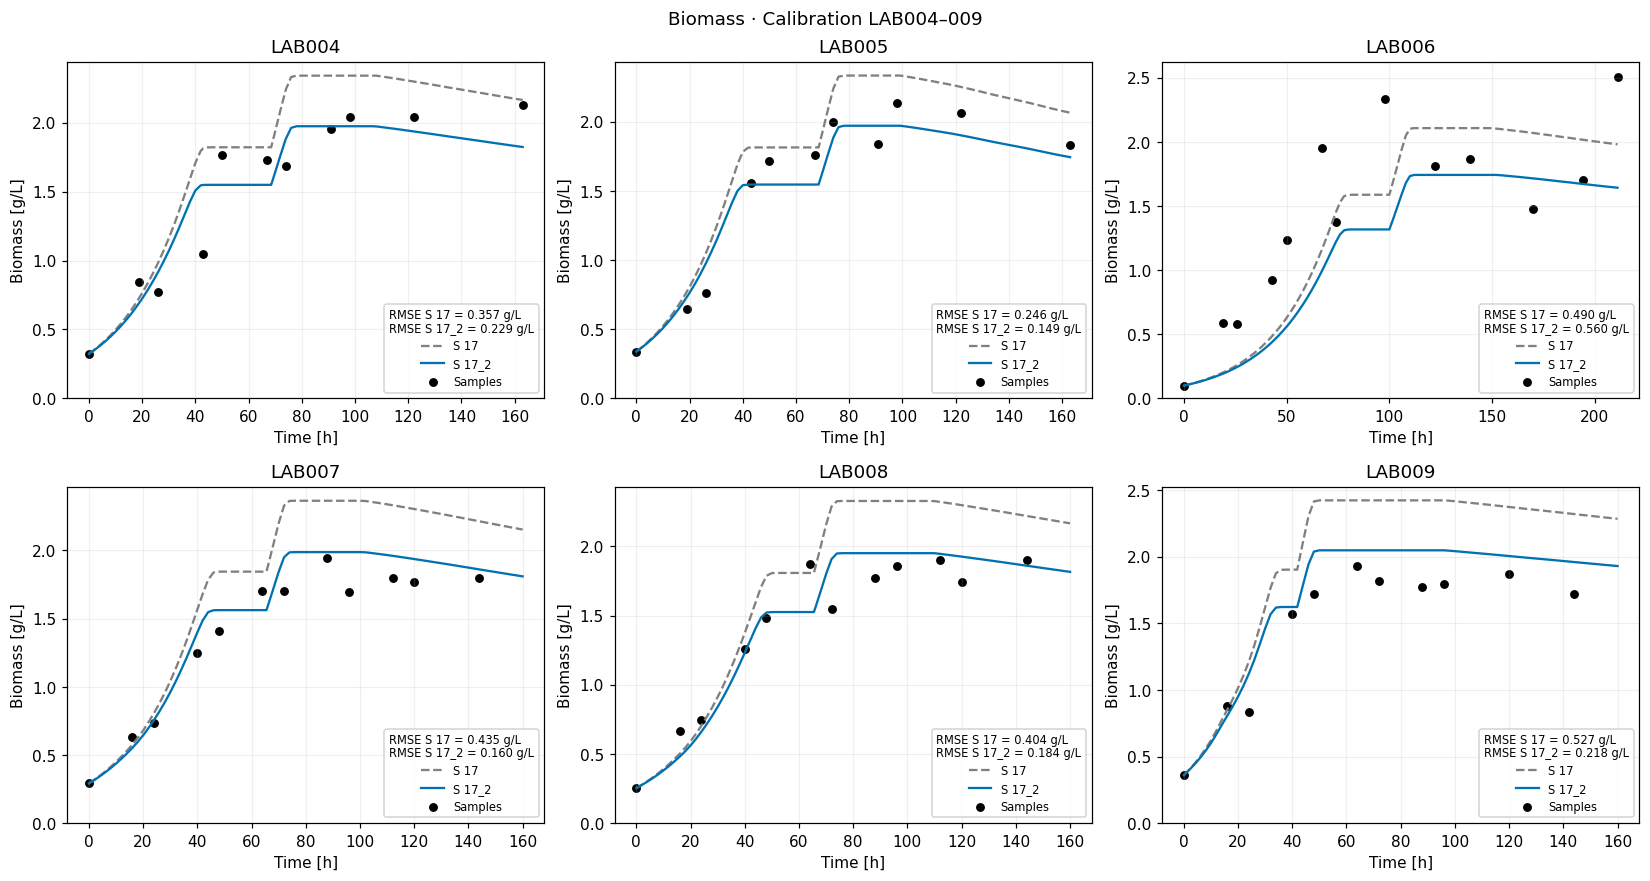

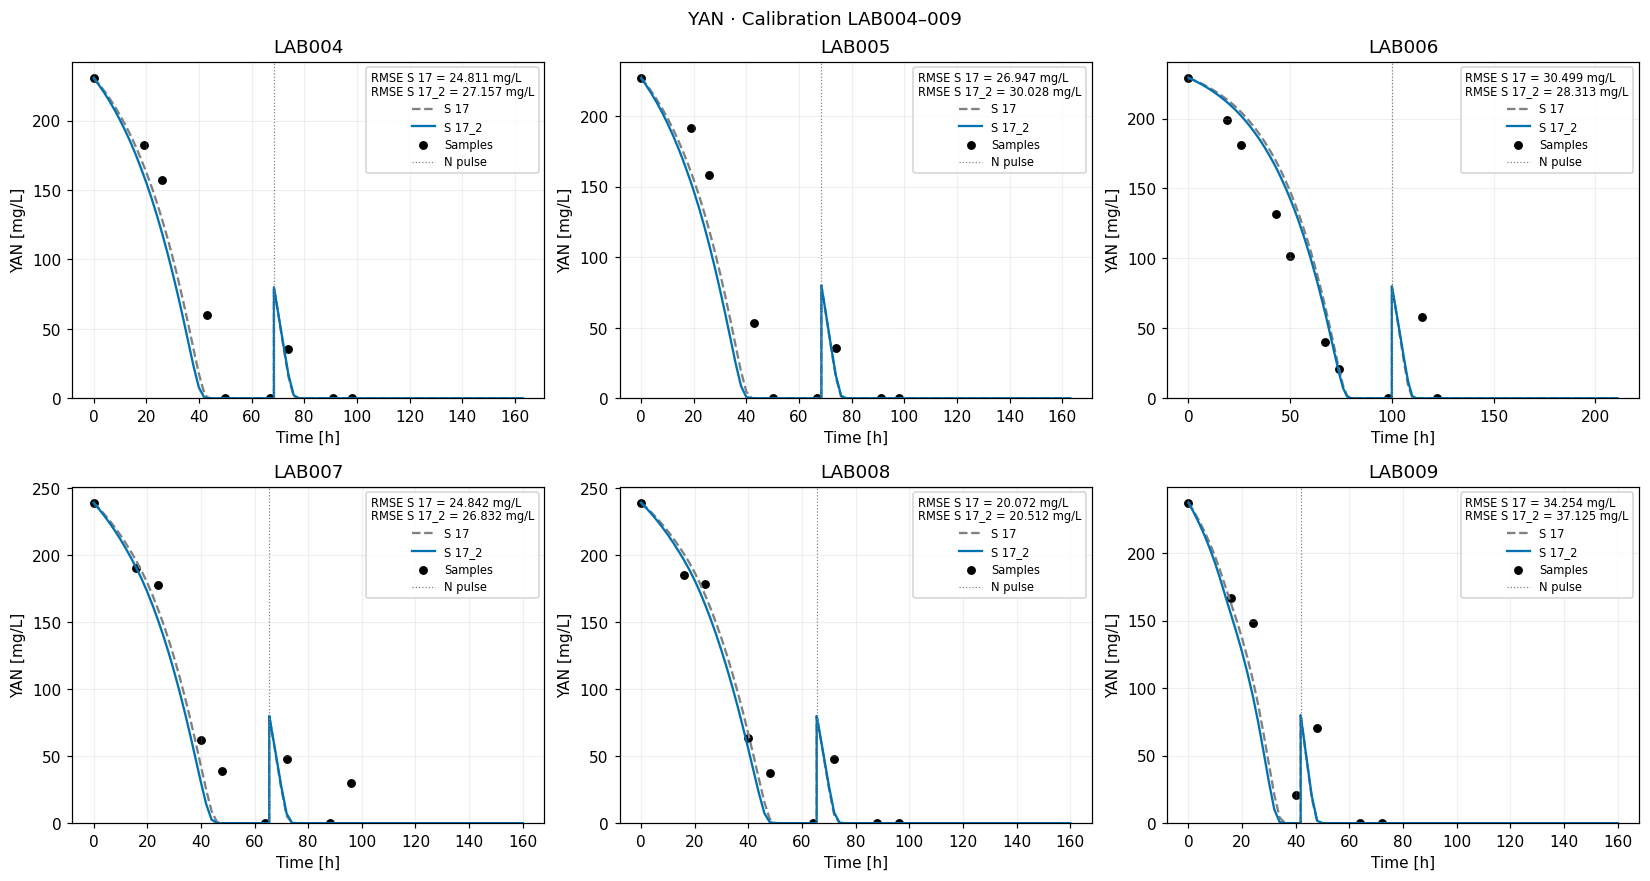

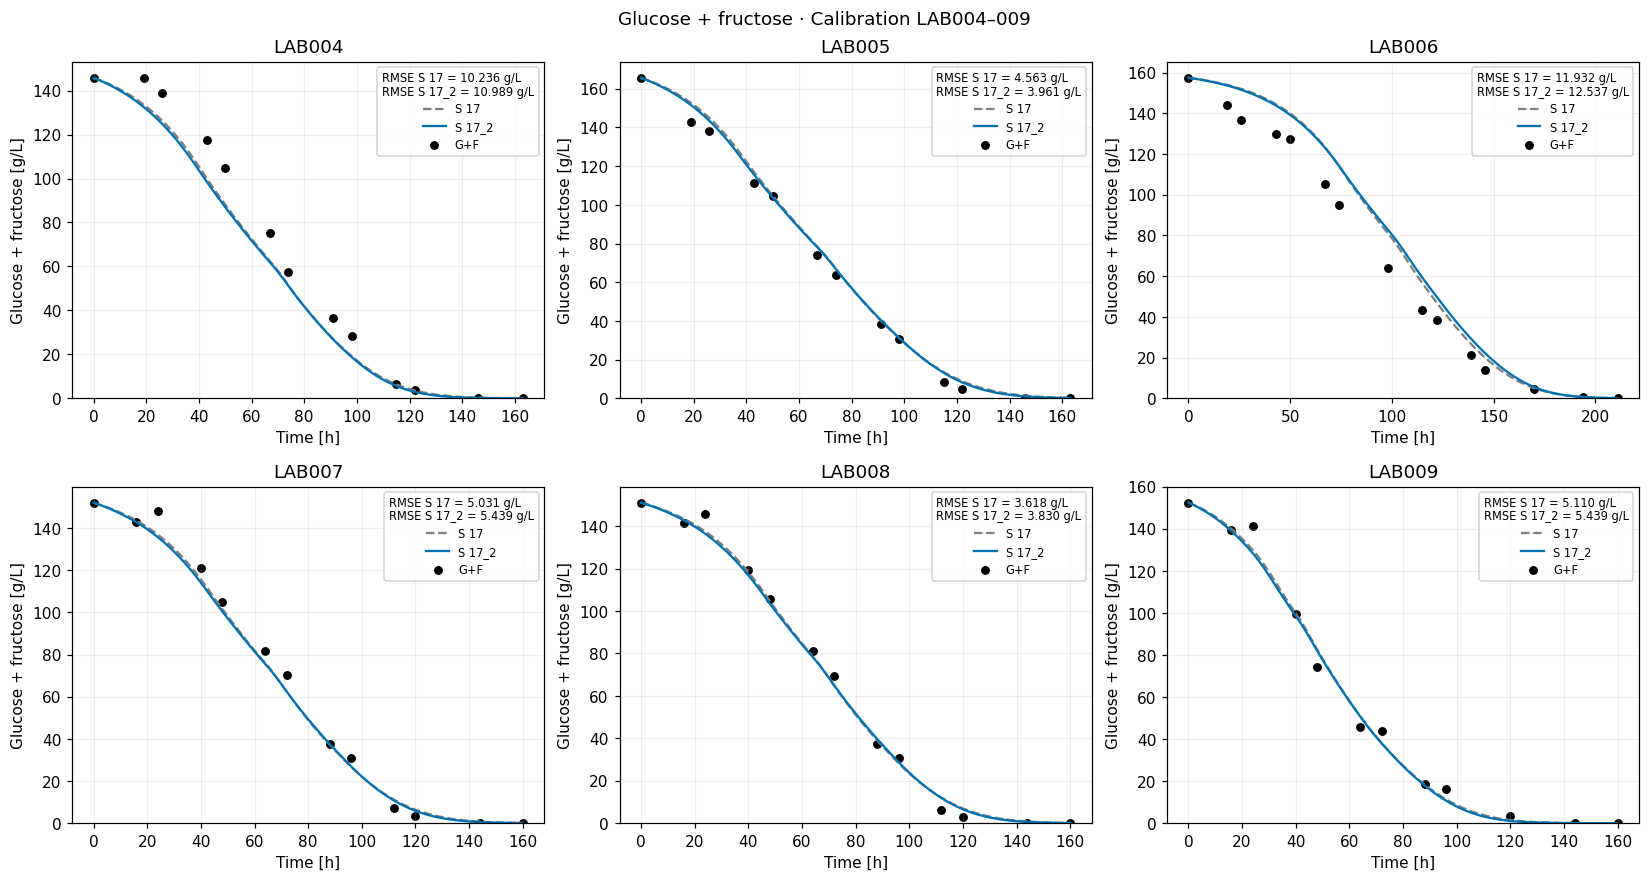

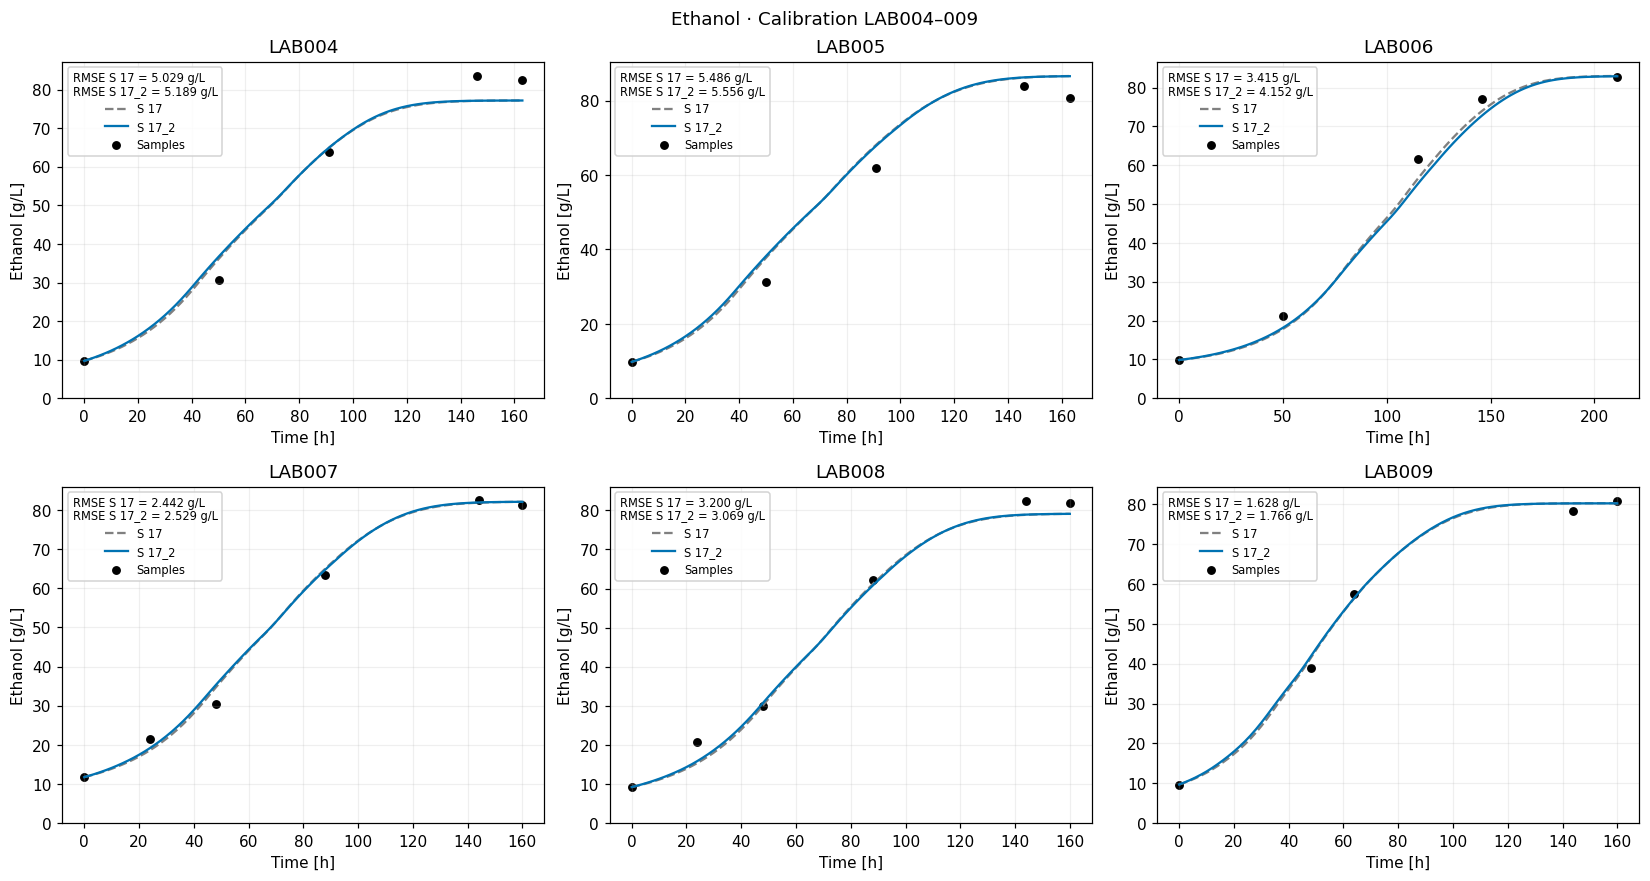

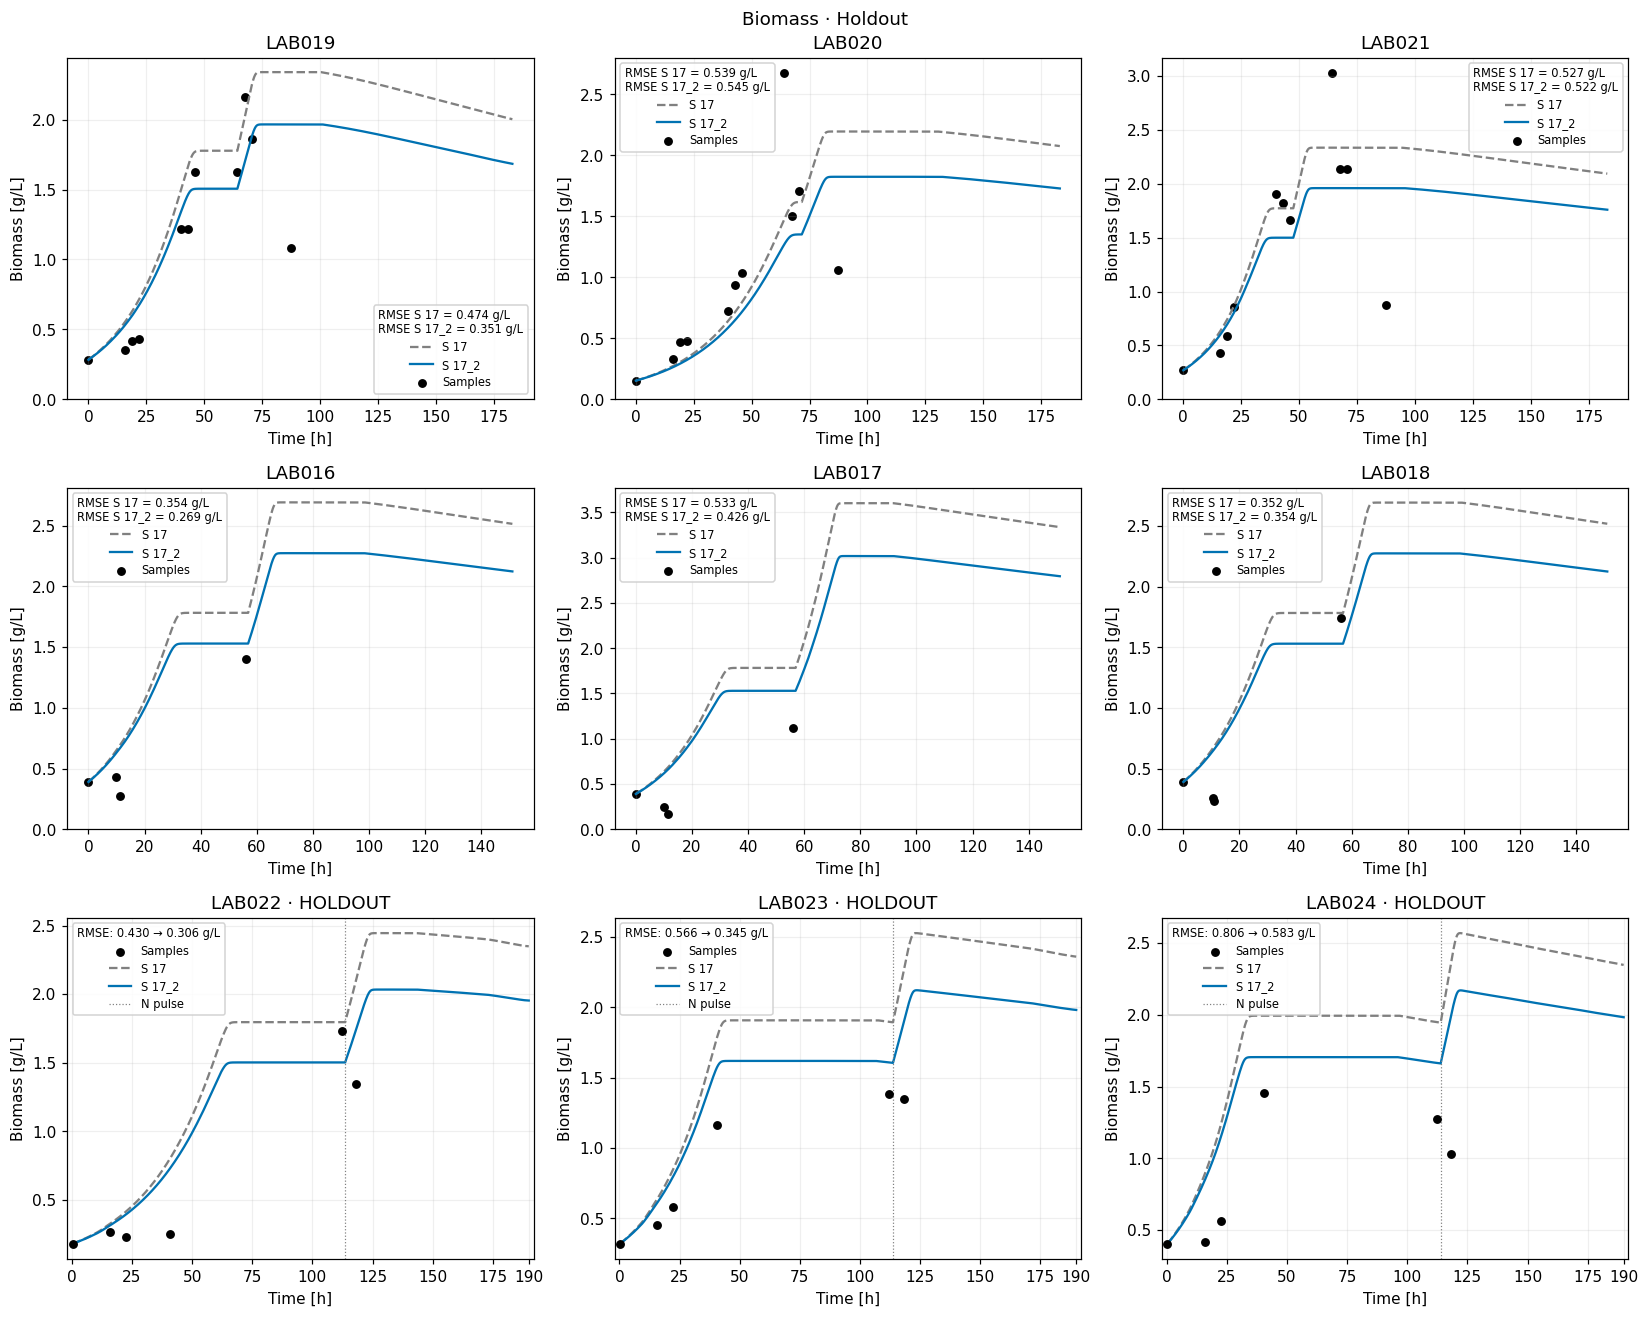

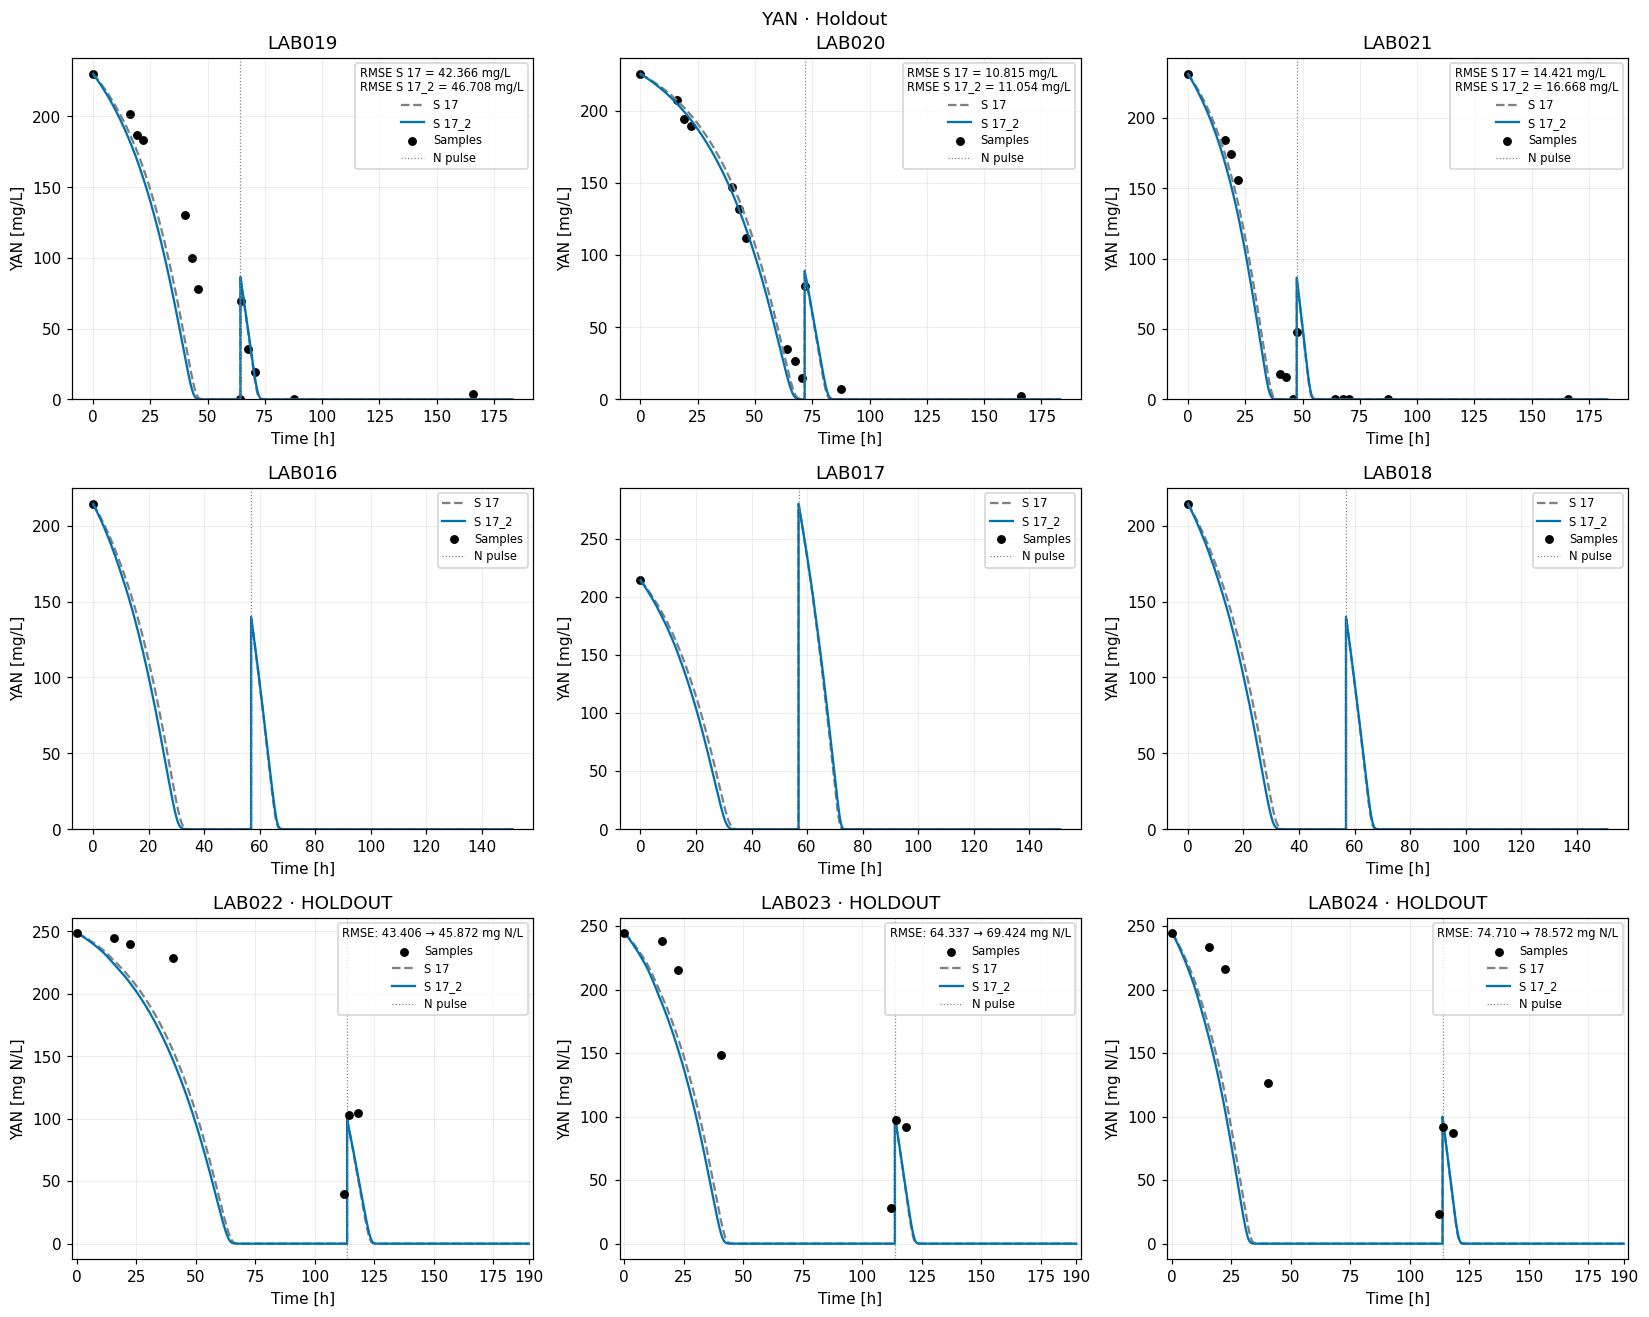

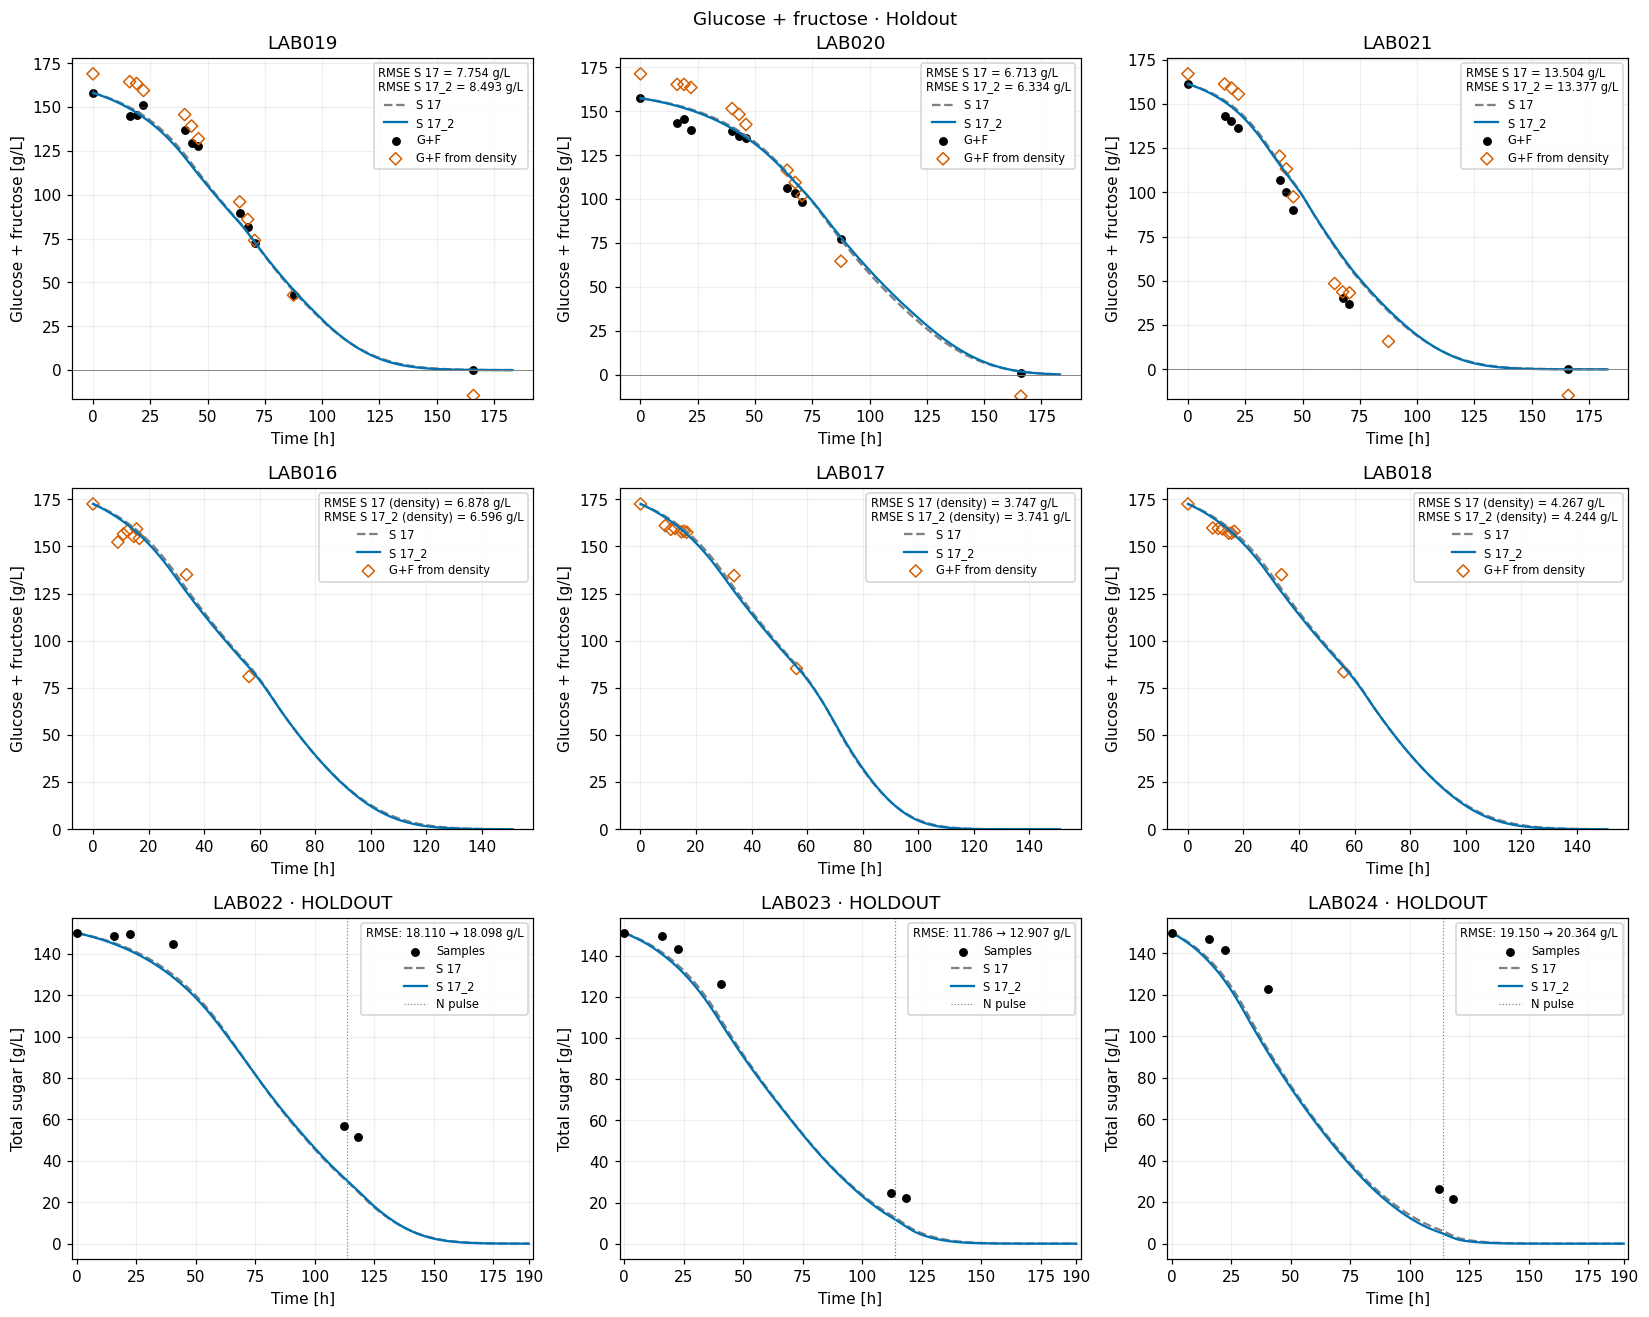

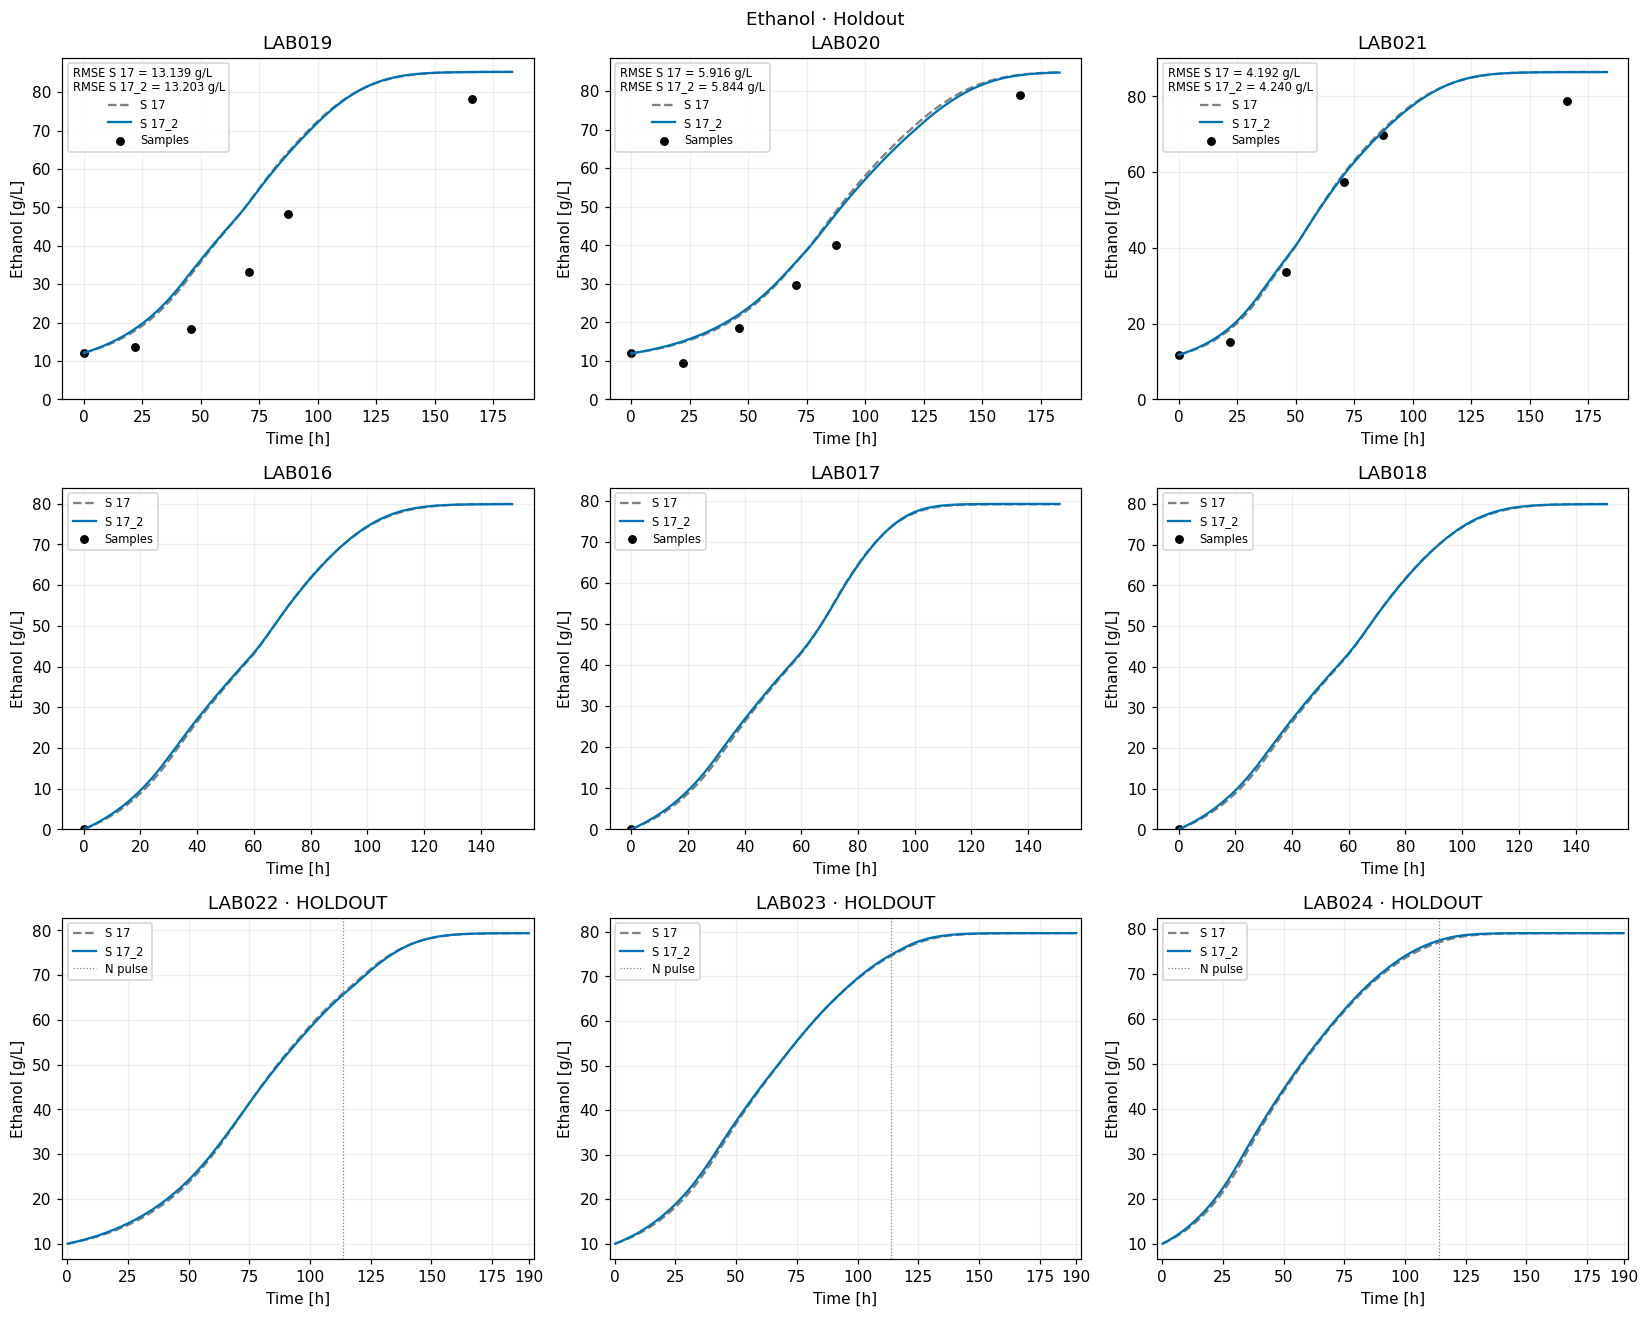

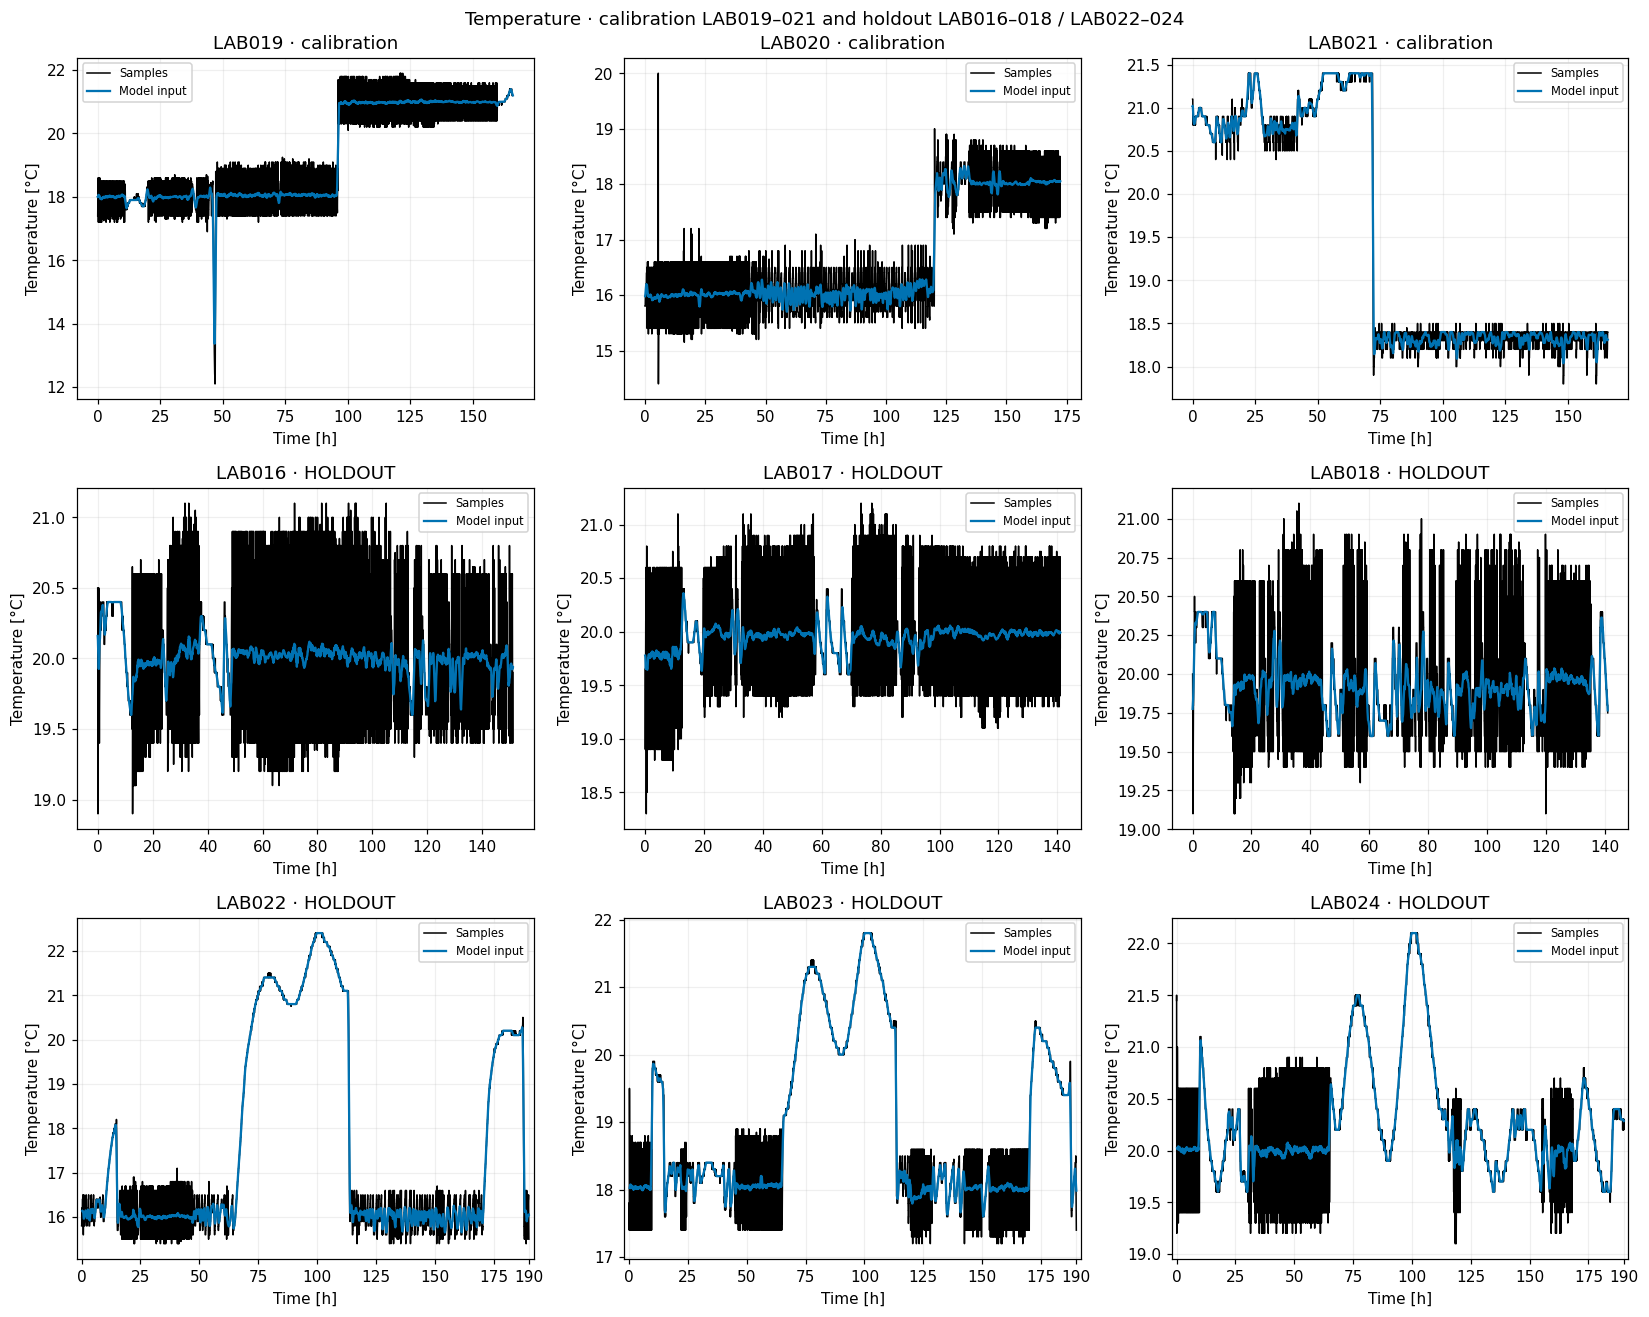

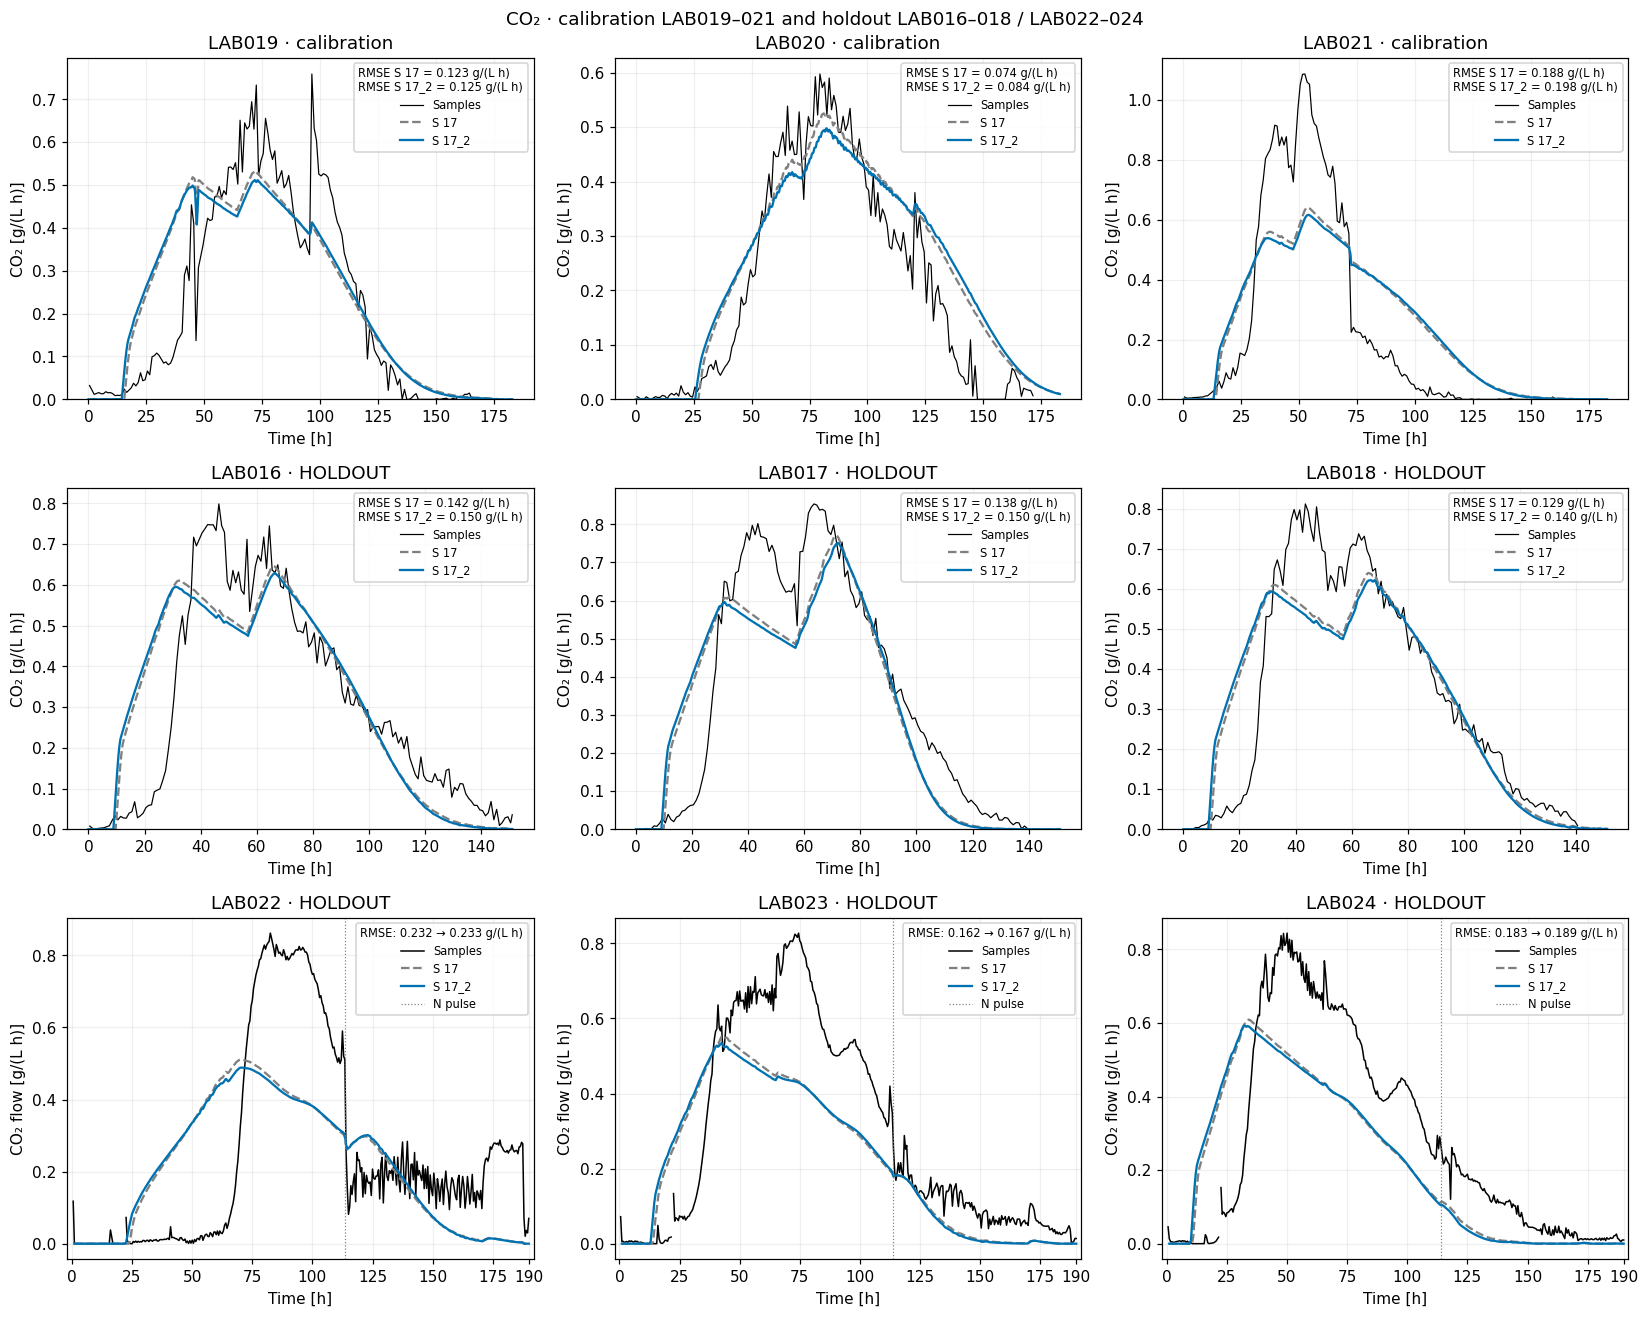

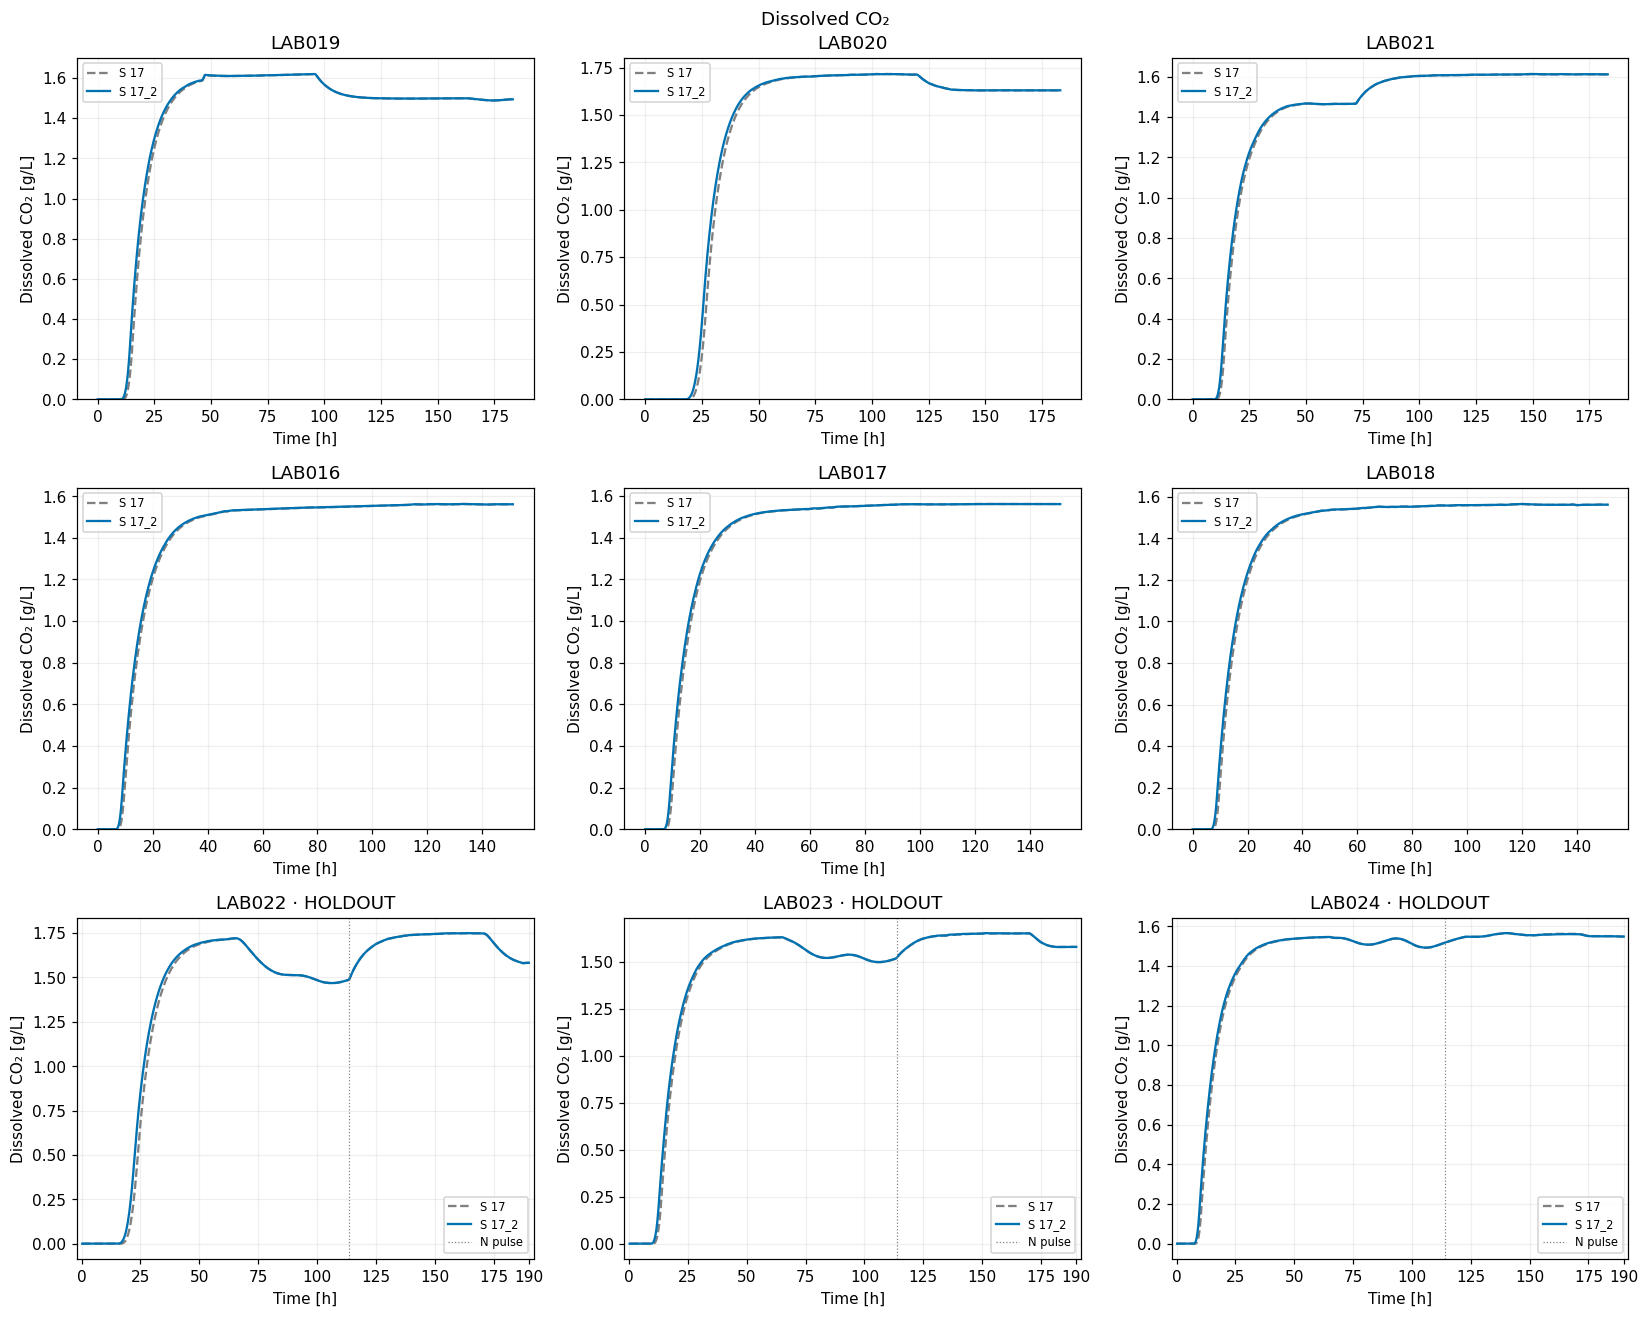

modelo                                   S 17     S 17_2
rol            LAB    variable n                        
Calibration    LAB004 E        4     5.028815   5.189246
                      N        8    24.811488  27.156553
                      S        12   10.236389  10.989012
                      X        10    0.356708   0.228521
               LAB005 E        4     5.485803   5.556327
                      N        8    26.946898  30.028123
                      S        12    4.562708   3.961470
                      X        10    0.246304   0.148901
               LAB006 E        4     3.414525   4.152349
                      N        9    30.499204  28.313094
                      S        14   11.932324  12.536734
                      X        12    0.489876   0.560214
               LAB007 E        5     2.442421   2.529066
                      N        8    24.841771  26.831639
                      S        12    5.030904   5.439020
                      X        11    0.435457   0.159895
               LAB008 E        5     3.200358   3.068597
                      N        8    20.071840  20.512326
                      S        12    3.617627   3.830386
                      X        11    0.404257   0.183674
               LAB009 E        4     1.628107   1.765604
                      N        6    34.253782  37.125179
                      S        11    5.109714   5.438530
                      X        10    0.527360   0.218390
Gas evaluation LAB016 CO2      152   0.141586   0.150356
               LAB017 CO2      141   0.138341   0.149557
               LAB018 CO2      141   0.128754   0.140028
               LAB019 CO2      166   0.122515   0.125014
               LAB020 CO2      172   0.074389   0.083631
               LAB021 CO2      166   0.187986   0.197757
Holdout        LAB016 X        3     0.354077   0.268707
               LAB017 X        3     0.533142   0.425895
               LAB018 X        3     0.351884   0.353837
               LAB019 E        5    13.138972  13.203483
                      N        12   42.366222  46.708129
                      S        11    7.753826   8.493020
                      X        10    0.473706   0.350873
               LAB020 E        5     5.916497   5.843769
                      N        12   10.815421  11.053679
                      S        11    6.712841   6.333618
                      X        10    0.538682   0.544806
               LAB021 E        5     4.191579   4.239692
                      N        12   14.420748  16.668088
                      S        9    13.504035  13.377236
                      X        10    0.527217   0.522022

,,,n,RMSE S 17,RMSE S 17_2
LAB,Variable,Unit,,,
LAB022,Biomass,g/L,5,0.4301,0.3059
LAB023,Biomass,g/L,5,0.5663,0.3450
LAB024,Biomass,g/L,5,0.8056,0.5831
LAB022,YAN,mg N/L,6,43.4057,45.8718
LAB023,YAN,mg N/L,6,64.3374,69.4242
LAB024,YAN,mg N/L,6,74.7098,78.5723
LAB022,Total sugar,g/L,5,18.1103,18.0978
LAB023,Total sugar,g/L,5,11.7861,12.9074
LAB024,Total sugar,g/L,5,19.1495,20.3645


,n,sesgo,RMSE
Modelo,,,
S 17,64,0.2282,0.4225
S 17_2,64,-0.0373,0.2968


n   sesgo    RMSE
LAB    Modelo                    
LAB004 S 17    10  0.2552  0.3567
       S 17_2  10 -0.0158  0.2285
LAB005 S 17    10  0.2168  0.2463
       S 17_2  10 -0.0500  0.1489
LAB006 S 17    12 -0.1914  0.4899
       S 17_2  12 -0.4059  0.5602
LAB007 S 17    11  0.3745  0.4355
       S 17_2  11  0.0992  0.1599
LAB008 S 17    11  0.2910  0.4043
       S 17_2  11  0.0187  0.1837
LAB009 S 17    10  0.4863  0.5274
       S 17_2  10  0.1843  0.2184

n   sesgo    RMSE
Periodo Modelo                    
Antes   S 17    30  0.0121  0.3445
        S 17_2  30 -0.1417  0.3548
Después S 17    34  0.4189  0.4809
        S 17_2  34  0.0548  0.2340

In [5]:
panels = [
    ("X", "Biomass", "g/L", holdout_biomass, "X_g_L", 1.),
    ("N", "YAN", "mg N/L", holdout_chemistry, "YAN for plot", 1000.),
]
if not HOLDOUT_SINGLE:
    panels.extend([
        ("G", "Glucose", "g/L", holdout_chemistry, "GLUCOSE-320", 1.),
        ("F", "Fructose", "g/L", holdout_chemistry, "Fructose (derived)", 1.),
    ])
panels.extend([
    ("S" if HOLDOUT_SINGLE else "GF", "Total sugar", "g/L", holdout_chemistry, "GLU-FRU-320", 1.),
    ("E", "Ethanol", "g/L", None, None, 1.),
    ("Cd", "Dissolved CO₂", "g/L", None, None, 1.),
    ("CO2", "CO₂ flow · 30-min mean", "g/(L h)", None, None, 1.),
])
holdout_metrics = []
holdout_panels = {panel[0]: panel[1:] for panel in panels}


def draw_lab022_024_row(axes, state):
    title, unit, sample_frame, column, factor = holdout_panels[state]
    for ax, lab in zip(axes, holdout_labs):
        errors = np.array([])
        errors16 = np.array([])
        if state == "CO2":
            prediction = holdout_mean_gas[lab]
            prediction16 = holdout_mean_gas16[lab]
            observed = holdout_flow[lab]
            ax.plot(observed.index, observed, color="black", lw=1, label="Samples")
            errors = (prediction - observed).dropna().to_numpy()
            errors16 = (prediction16 - observed).dropna().to_numpy()
        elif state == "Cd":
            prediction = holdout_gas[lab]["Cd"]
            prediction16 = holdout_gas16[lab]["Cd"]
        else:
            prediction = holdout_plot[lab][state] * factor
            prediction16 = holdout_plot16[lab][state] * factor
            if sample_frame is not None:
                samples = sample_frame.loc[sample_frame["lab"].eq(lab)].dropna(subset=[column])
                ax.scatter(samples["hours"], samples[column], c="black", s=23, label="Samples", zorder=5)
                evaluation = samples.loc[samples["sample"].ne("01")]
                at_sample = holdout_kinetic[lab].loc[evaluation["hours"].to_numpy(), state].to_numpy()
                errors = at_sample * factor - evaluation[column].to_numpy()
                at_sample16 = holdout_kinetic16[lab].loc[evaluation["hours"].to_numpy(), state].to_numpy()
                errors16 = at_sample16 * factor - evaluation[column].to_numpy()
        ax.plot(prediction16.index, prediction16, c="gray", ls="--", lw=1.5, label="S 17")
        ax.plot(prediction.index, prediction, c="#0072B2", lw=1.5, label="S 17_2")
        ax.axvline(holdout_nutrition[lab], c="gray", ls=":", lw=.8, label="N pulse")
        legend_title = None
        if len(errors):
            rmse = np.sqrt(np.mean(errors**2))
            assert len(errors16) == len(errors)
            rmse16 = np.sqrt(np.mean(errors16**2))
            holdout_metrics.append({"LAB": lab, "Variable": title, "n": len(errors),
                                    "RMSE S 17": rmse16, "RMSE S 17_2": rmse, "Unit": unit})
            legend_title = f"RMSE: {rmse16:.3f} → {rmse:.3f} {unit}"
        ax.set(title=f"{lab} · HOLDOUT", xlabel="Time [h]", xlim=(-2, holdout_horizon + 2),
               xticks=[0, 25, 50, 75, 100, 125, 150, 175, 190])
        ax.grid(alpha=.2)
        ax.set_ylabel(f"{title.split(chr(183))[0].strip()} [{unit}]")
        ax._rmse_text = legend_title


comparison=[]


def finish_figure(fig,axs,title):
 fig.suptitle(title,y=.99)
 fig.tight_layout(pad=.7,h_pad=1.2,w_pad=.9)
 for ax in axs.flat:
  handles,labels=ax.get_legend_handles_labels();unique=dict(zip(labels,handles))
  legend=ax.legend(unique.values(),unique.keys(),loc='best',fontsize=7.5,framealpha=.85,title=getattr(ax,'_rmse_text',None),title_fontsize=7.5)
  assert len(legend.get_texts())==len(unique)
 assert not fig.legends
 plt.show()

def draw_group(group,reference,reduced,holdout=False):
 for s,title in [('X','Biomass'),('N','YAN'),('S','Glucose + fructose'),('E','Ethanol')]:
  scale=1000 if s=='N' else 1;unit='mg/L' if s=='N' else 'g/L'
  rows = 3 if holdout else 2
  fig,axs=plt.subplots(rows,3,figsize=(15,4*rows))
  for ax,item in zip(axs.flat,group):
   b=batches[item] if holdout else item;lab=b.batch;a=plotframe_s(reference[lab]);r=plotframe_s(reduced[lab])
   ax.plot(a.index,a[s]*scale,c='gray',ls='--',label='S 17')
   ax.plot(r.index,r[s]*scale,c='#0072B2',label='S 17_2')
   label='G+F' if s=='S' else 'Samples'
   if not holdout:
    yy,sg,mask=targets(b,s);tt=b.time
    ax.scatter(tt[mask],yy[mask]*scale,c='black',s=23,label=label)
   else:
    col='GF' if s=='S' else s
    if lab in TRAIN:
     z=chemical_observations(v.chem,lab,col);tt=z.t_h.to_numpy();yy=z[CHEMICAL_COLUMNS[col]].to_numpy()
    elif s=='X':
     z=v.biomass.loc[v.biomass.lab.eq(lab)].dropna(subset=['t_h','X_viable_g_l']);tt=z.t_h.to_numpy();yy=z.X_viable_g_l.to_numpy()
    else:tt=np.array([]);yy=np.array([])
    mask=np.isfinite(yy)&(tt>0)&(tt<=v.horizons[lab]);shown=np.isfinite(yy)&~np.isclose(tt,0.)
    if shown.any():ax.scatter(tt[shown],yy[shown]*scale,c='black',s=23,label=label)
    if s=='S':
     z=v.density.loc[v.density.lab.eq(lab)].dropna(subset=['t_h','density_g_l'])
     ax.scatter(z.t_h,2.5*(z.density_g_l-1000),marker='D',facecolors='none',edgecolors='#D55E00',s=32,label='G+F from density')
   # Use the actual corrected model initial value, never the superseded biomass observation.
   if not (holdout and s=='S' and lab not in TRAIN):
    initial_point=ax.scatter([0.],[r[s].iloc[0]*scale],c='black',s=23,label=label)
    assert np.allclose(initial_point.get_offsets(),[[0.,r[s].iloc[0]*scale]])
   errors=[]
   for model,f,vals in [('S 17',a,a[s]),('S 17_2',r,r[s])]:
    if mask.any():
     # Same scoring operator and samples as diagnostic 17.
     err=(np.interp(tt[mask],f.index,vals)-yy[mask])*scale
     value=float(np.sqrt(np.mean(err**2)));errors.append(f'RMSE {model} = {value:.3f} {unit}')
     comparison.append(dict(LAB=lab,rol='Holdout' if holdout else 'Calibration',variable=s,modelo=model,n=int(mask.sum()),RMSE=value,sesgo=float(err.mean())))
   if holdout and s=='S' and not mask.any():
    # Label density-based errors explicitly; do not add them to the chemical scoring table.
    density_mask=z.t_h.gt(0)&z.t_h.le(v.horizons[lab]);dt=z.loc[density_mask,'t_h'].to_numpy();dy=2.5*(z.loc[density_mask,'density_g_l'].to_numpy()-1000)
    for model,f,vals in [('S 17',a,a[s]),('S 17_2',r,r[s])]:
     if len(dt):errors.append(f'RMSE {model} (density) = {np.sqrt(np.mean((np.interp(dt,f.index,vals)-dy)**2)):.3f} g/L')
   if errors:ax._rmse_text='\n'.join(errors)
   if s=='N':
    for t,d in b.pulses['N']:ax.axvline(t,c='gray',ls=':',lw=.8,label='N pulse')
   ax.set(title=lab,xlabel='Time [h]',ylabel=title+f' [{unit}]',ylim=(0,None));ax.grid(alpha=.2)
   if holdout and s=='S':
    ax.set_ylim(bottom=min(0.,float((2.5*(z.density_g_l-1000)).min())*1.15));ax.axhline(0,c='gray',lw=.6)
  if holdout:draw_lab022_024_row(axs[-1],s)
  finish_figure(fig,axs,title+' · '+('Holdout' if holdout else 'Calibration LAB004–009'))

# Perfiles térmicos de los entrenamientos: medianas de 30 minutos (negro) y perfil filtrado usado por las simulaciones (azul).
fig,axs=plt.subplots(2,3,figsize=(15,8))
for ax,b in zip(axs.flat,treated):
 p=profiles[b.batch].loc[lambda p: p.t_h.between(b.time[0], b.time[-1])]
 ax.plot(p.t_h,p['T'],c='black',lw=1,label='Samples')
 ax.plot(b.time,b.temperature_c,c='#0072B2',lw=1.5,label='Model input')
 assert len(p)==len(p.dropna(subset=['t_h','T'])) and np.isfinite(b.temperature_c).all()
 assert set(ax.get_legend_handles_labels()[1])=={'Samples','Model input'}
 ax.set(title=b.batch,xlabel='Time [h]',ylabel='Temperature [°C]');ax.grid(alpha=.2)
finish_figure(fig,axs,'Temperature · Calibration LAB004–009')
draw_group(treated,original_train,reduced_train)
draw_group(LABS,original_cores,reduced_cores,True)

# Perfiles térmicos LAB016–024 con la misma disposición de filas que la figura de CO₂.
def temperature_panel(ax,lab,role,measured_t,measured,input_t,input_T):
 ax.plot(measured_t,measured,c='black',lw=1,label='Samples')
 ax.plot(input_t,input_T,c='#0072B2',lw=1.5,label='Model input')
 ax.set(title=lab+role,xlabel='Time [h]',ylabel='Temperature [°C]');ax.grid(alpha=.2)
 assert np.isfinite(np.asarray(measured,float)).any() and np.isfinite(np.asarray(input_T,float)).all()
fig,axs=plt.subplots(3,3,figsize=(15,12))
for ax,lab in zip(axs[:2].flat,LABS):
 tv=v.temperature[lab]
 batch=batches[lab];end=v.horizons[lab]
 measured=tv.loc[tv.time_h.between(0,end)]
 times=np.r_[batch.time[batch.time<end],end]
 model_input=np.interp(times,batch.time,batch.temperature_c)
 temperature_panel(ax,lab,' · calibration' if lab in TRAIN else ' · HOLDOUT',
                   measured.time_h,measured.raw_1min,times,model_input)
for ax,lab in zip(axs[-1],holdout_labs):
 profile=holdout_temperature_profiles[lab]
 measured=profile.loc[profile.time_h.between(0, holdout_horizon)]
 batch=holdout_batches[lab]
 temperature_panel(ax,lab,' · HOLDOUT',measured.time_h,measured.raw_1min,batch.time,batch.temperature_c)
 ax.set(xlim=(-2,holdout_horizon+2),xticks=[0,25,50,75,100,125,150,175,190])
finish_figure(fig,axs,'Temperature · calibration LAB019–021 and holdout LAB016–018 / LAB022–024')
fig,axs=plt.subplots(3,3,figsize=(15,12))
for ax,lab in zip(axs[:2].flat,LABS):
 o=obs[lab];ax.plot(o.time_h,o.co2_raw_g_l_h,c='black',lw=.8,label='Samples');errors=[]
 for model,cur,color,style in [('S 17',original_gas,'gray','--'),('S 17_2',reduced_gas,'#0072B2','-')]:
  f=cur[lab];ax.plot(f.index,f.qpred,c=color,ls=style,label=model);err=np.interp(o.time_h,f.index,f.qpred)-o.co2_raw_g_l_h
  value=float(np.sqrt(np.mean(err**2)));errors.append(f'RMSE {model} = {value:.3f} g/(L h)')
  comparison.append(dict(LAB=lab,rol='Gas evaluation',variable='CO2',modelo=model,n=len(o),RMSE=value,sesgo=float(err.mean())))
 ax._rmse_text='\n'.join(errors)
 ax.set(title=lab+(' · calibration' if lab in TRAIN else ' · HOLDOUT'),xlabel='Time [h]',ylabel='CO₂ [g/(L h)]',ylim=(0,None));ax.grid(alpha=.2)
draw_lab022_024_row(axs[-1], 'CO2')
finish_figure(fig,axs,'CO₂ · calibration LAB019–021 and holdout LAB016–018 / LAB022–024')
# Comparación de las trayectorias internas de CO₂ en las mismas tres filas.
fig, axs = plt.subplots(3, 3, figsize=(15, 12))
for ax, lab in zip(axs[:2].flat, LABS):
 for model, curves, color, style in [
     ('S 17', original_gas, 'gray', '--'), ('S 17_2', reduced_gas, '#0072B2', '-')]:
  curve = curves[lab]
  ax.plot(curve.index, curve.Cd, c=color, ls=style, label=model)
 ax.set(title=lab, xlabel='Time [h]', ylabel='Dissolved CO₂ [g/L]', ylim=(0,None))
 ax.grid(alpha=.2)
draw_lab022_024_row(axs[-1], 'Cd')
finish_figure(fig, axs, 'Dissolved CO₂')
metrics_s=pd.DataFrame(comparison);display(metrics_s.pivot(index=['rol','LAB','variable','n'],columns='modelo',values='RMSE'));


assert set(metrics_s.modelo) == {"S 17", "S 17_2"}
display(pd.DataFrame(holdout_metrics).set_index(["LAB", "Variable", "Unit"]).round(4))
biomass_rows = []
for model, frames in training_curves.items():
    for b in treated:
        y, _, mask = targets(b, "X")
        for t, error in zip(b.time[mask], frames[b.batch].X.to_numpy()[mask] - y[mask]):
            biomass_rows.append(dict(LAB=b.batch, Modelo=model,
                                     Periodo="Antes" if t <= b.pulses['N'][0][0] else "Después",
                                     Error=error))
biomass_errors = pd.DataFrame(biomass_rows)
def biomass_summary(keys):
    return biomass_errors.groupby(keys).Error.agg(n="size", sesgo="mean",
                                                   RMSE=lambda x: np.sqrt(np.mean(x**2)))
overall = biomass_summary(["Modelo"])
by_lab = biomass_summary(["LAB", "Modelo"])
by_period = biomass_summary(["Periodo", "Modelo"])
assert overall.n.eq(64).all()
display(overall.round(4))
display(by_lab.round(4))
display(by_period.round(4))


## Muerte celular durante la formación de biomasa y el consumo de YAN

Se estudia el vector calibrado principal, sin reajustarlo. El análisis se concentra en LAB004–009 porque sus mediciones determinan el rendimiento de biomasa respecto al nitrógeno. Se mantienen las condiciones iniciales, los perfiles térmicos y las nutriciones. El coeficiente de referencia de muerte permanece fijo en 0,00044 h⁻¹; la muerte efectiva se calcula con la ley original, que depende de temperatura, etanol y umbral térmico.

Se añaden dos contadores a los balances químicos: biomasa formada acumulada y biomasa muerta acumulada. No son estados nuevos que modifiquen la química:

\[
B(t)=\int_{t_0}^t\mu X\,dt,\qquad D(t)=\int_{t_0}^t k_dX\,dt.
\]
\[
X(t)-X_0=B(t)-D(t),\qquad B(t)=Y_{XN}\left[N_0+\sum_{t_j<t}\Delta N_j-N(t)\right].
\]

Las muestras en la hora exacta de una nutrición representan el estado previo al salto. Se verifica el cierre numérico de ambas identidades y la concordancia con el simulador original. La integración de diagnóstico utiliza tolerancias estrictas y pasos máximos de 0,1 y 0,05 h para comprobar estabilidad.

La ventana principal termina al alcanzar el 99 % de la formación acumulada de biomasa de cada lote. Es una definición operativa basada en la trayectoria, no en el último muestreo. Además, se integra por separado la muerte mientras el YAN del modelo es al menos 1 mg N/L y 20 mg N/L. Así se distingue la pérdida durante el crecimiento de la pérdida posterior. El umbral de 20 mg N/L permite comparar con el tratamiento de las observaciones de YAN de la calibración; los cálculos usan el YAN continuo del modelo.

Se simula también el caso sin muerte, manteniendo todos los parámetros y entradas. Este contraste aísla el efecto de la mortalidad supuesta; no es una nueva calibración ni una estimación de la mortalidad real.

Para dimensionar la compensación propuesta se calcula, hasta el 99 % de formación, la muerte que haría falta con rendimientos hipotéticos de 10 y 20 g biomasa/g N, conservando el nitrógeno consumido y el incremento neto de biomasa de la predicción actual:
\[
D_{\mathrm{requerida}}=Y_{XN}^{\mathrm{hipotético}}\,N_{\mathrm{consumido}}-(X-X_0).
\]
Estos valores son referencias contables, no parámetros recomendados ni simulaciones recalibradas. El rendimiento calibrado ya relaciona el nitrógeno consumido con la formación bruta; no se debe sumar la muerte una segunda vez al interpretarlo.


La condición de activación térmica impone \(k_d=0\) si \(T<T_D(E)\); los coeficientes y la función de umbral se conservan exactamente como en el modelo original.

In [6]:
mortality_model="S"
mortality_parameters=ps.copy()
mortality_reference=simulate_s
from dataclasses import replace
from scipy.integrate import solve_ivp as mortality_solve_ivp

mortality_step = 0.1  # h; malla de diagnóstico, sin modificar entradas ni parámetros.
mortality_training = {b.batch:b for b in treated} if mortality_model == "S" else training
assert set(mortality_training)=={f"LAB{i:03}" for i in range(4,10)}
mortality_physical = ["X","N","G","F","E"] if mortality_model=="GF" else ["X","N","S","E"]
mortality_sugars = (2,3) if mortality_model=="GF" else (2,)

def mortality_rhs(batch, parameters, no_death=False):
    def rhs(t,state):
        y=state[:len(mortality_physical)].copy()
        x=max(float(y[0]),0.)
        if mortality_model=="GF":
            q=kin.kinetic_terms(parameters,kin.temperature_at(batch,t),*y)
            mu=q["mu"] if any(y[i]>0 for i in mortality_sugars) else 0.
            kd=q["kd"]
            dy=np.asarray(kin.rhs(t,y,parameters,batch)).copy()
            growth=q["mu"]*x
            if y[2]<=0 or y[3]<=0:
                if y[2]<=0 and y[3]<=0:
                    dy[0]-=growth;dy[1]+=growth/parameters["Yxn"]
                if y[2]<=0:dy[2]+=growth/parameters["Yxg"]
                if y[3]<=0:dy[3]+=growth/parameters["Yxf"]
        else:
            mu,beta,kd,maintenance=terms_s(t,y,parameters,batch)
            dy=np.array([(mu-kd)*x,-mu*x/parameters["Yxn"],
                         -(mu/YXS+beta/parameters["Yes"]+maintenance)*x,beta*x])
        if no_death:dy[0]+=kd*x;kd=0.
        for index in mortality_sugars:
            if y[index]<=0:dy[index]=0.
        # Integrales de formación y muerte; los últimos dos contadores separan
        # la muerte mientras N es al menos 1 y 20 mg N/L, respectivamente.
        birth=mu*x;death=kd*x
        return np.r_[dy,birth,death,death if y[1]>=.001 else 0.,death if y[1]>=.020 else 0.]
    return rhs

def mortality_integrate(batch, parameters, no_death=False, step=mortality_step):
    number=len(mortality_physical)
    initial=[batch.initials[k] for k in (mortality_physical if mortality_model=="GF" else ["X","N"])]
    if mortality_model=="S":initial += [batch.initials["G"]+batch.initials["F"],batch.initials["E"]]
    state=np.r_[initial,np.zeros(4)]
    start=float(batch.time[0]);finish=float(batch.time[-1]);now=start
    times=np.unique(np.r_[np.arange(start,finish,step),batch.time,finish])
    doses={}
    for t,d in batch.pulses.get("N",()):
        if start<t<=finish:doses[float(t)]=doses.get(float(t),0.)+d
    records={start:state.copy()};jumps=[]
    original_rhs=mortality_rhs(batch,parameters,no_death)
    for end in sorted(set([finish,*doses])):
        while now<end:
            active=[i for i in mortality_sugars if state[i]>0]
            frozen=[i for i in mortality_sugars if i not in active]
            def rhs(t,y):
                physical=y.copy()
                physical[active]=np.maximum(physical[active],np.finfo(float).tiny)
                physical[frozen]=0.
                derivative=original_rhs(t,physical)
                derivative[frozen]=0.
                return derivative
            events=[]
            for index in active:
                def depletion(t,y,index=index):return y[index]
                depletion.terminal=True;depletion.direction=-1
                events.append(depletion)
            sol=mortality_solve_ivp(rhs,(now,end),state,method="LSODA",dense_output=True,
                events=events or None,rtol=2e-8,atol=2e-10,max_step=step)
            assert sol.success and np.isfinite(sol.y).all(),sol.message
            stop=float(sol.t[-1])
            requested=times[(times>now)&(times<=stop)]
            if len(requested):records.update({float(t):y.copy() for t,y in zip(requested,sol.sol(requested).T)})
            state=sol.y[:,-1].copy()
            if sol.status==1:
                hit=[i for i,hits in enumerate(sol.t_events) if len(hits)]
                assert len(hit)==1
                state[active[hit[0]]]=0.
            assert stop>now
            records[stop]=state.copy();now=stop
        if end in doses:
            before=state.copy();state[1]+=doses[end]
            jumps.append((end,before,state.copy()))
    frame=pd.DataFrame.from_dict(records,orient="index",columns=mortality_physical+["Formada","Muerta","Muerta_N1","Muerta_N20"]).sort_index()
    assert frame[mortality_physical].to_numpy().min()>-1e-6
    frame[mortality_physical]=frame[mortality_physical].clip(lower=0.)
    # Las filas en la hora exacta de una nutrición representan el estado previo.
    received=np.array([sum(d for t,d in doses.items() if t<time) for time in frame.index])
    uptake=batch.initials["N"]+received-frame.N.to_numpy()
    n_error=np.max(np.abs(uptake-frame.Formada.to_numpy()/parameters["Yxn"]))
    x_error=np.max(np.abs(frame.X.to_numpy()-initial[0]-frame.Formada.to_numpy()+frame.Muerta.to_numpy()))
    assert n_error<2e-6 and x_error<2e-6,(batch.batch,n_error,x_error)
    frame.attrs.update(jumps=jumps,n_balance_error=n_error,x_balance_error=x_error)
    return frame

mortality_curves={};mortality_without_death={};mortality_rows=[];mortality_checks=[]
for lab,batch in mortality_training.items():
    frame=mortality_integrate(batch,mortality_parameters)
    counter=mortality_integrate(batch,mortality_parameters,no_death=True)
    mortality_curves[lab]=frame;mortality_without_death[lab]=counter
    reference=(mortality_reference(batch,mortality_parameters))
    errors=np.abs(frame.loc[reference.index,mortality_physical].to_numpy()-reference[mortality_physical].to_numpy())
    assert errors.max()<5e-4,(lab,errors.max())
    total_birth=float(frame.Formada.iloc[-1]);assert total_birth>0
    t99=float(np.interp(.99*total_birth,frame.Formada,frame.index))
    birth99=float(np.interp(t99,frame.index,frame.Formada))
    dead99=float(np.interp(t99,frame.index,frame.Muerta))
    uptake99=birth99/mortality_parameters["Yxn"]
    net99=birth99-dead99
    kd_values=[];kd_with_n=[];death_times=[]
    for t,row in frame.iterrows():
        if mortality_model=="GF":kd=kin.kinetic_terms(mortality_parameters,kin.temperature_at(batch,t),*row[mortality_physical])["kd"]
        else:kd=terms_s(t,row[mortality_physical].to_numpy(),mortality_parameters,batch)[2]
        kd_values.append(kd)
        if row.N>=.001:kd_with_n.append(kd)
        if kd>0:death_times.append(t)
    dead=float(frame.Muerta.iloc[-1])
    no_death_x=np.interp(frame.index,counter.index,counter.X)
    no_death_n=np.interp(frame.index,counter.index,counter.N)
    mortality_rows.append({"LAB":lab,"Horizonte [h]":frame.index[-1],"99 % de formación [h]":t99,
        "Biomasa formada total [g/L]":total_birth,"Muerte hasta 99 % [g/L]":dead99,
        "Muerte/formación hasta 99 % [%]":100*dead99/birth99,
        "Muerte con YAN ≥1 mg N/L [g/L]":float(frame.Muerta_N1.iloc[-1]),
        "Muerte con YAN ≥20 mg N/L [g/L]":float(frame.Muerta_N20.iloc[-1]),
        "Muerte total [g/L]":dead,"Muerte posterior al 99 % [g/L]":dead-dead99,
        "Primera activación de muerte [h]":min(death_times) if death_times else np.nan,
        "Máximo kd con YAN ≥1 mg N/L [1/h]":max(kd_with_n,default=0.),"Máximo kd [1/h]":max(kd_values),
        "YAN consumido hasta 99 % [mg N/L]":1000*uptake99,
        "Rendimiento neto hasta 99 % [g/g]":net99/uptake99,
        "Muerte requerida para YXN=10 hasta 99 % [g/L]":10*uptake99-net99,
        "Muerte requerida para YXN=20 hasta 99 % [g/L]":20*uptake99-net99,
        "Máxima diferencia X sin muerte [g/L]":float(np.max(np.abs(no_death_x-frame.X))),
        "Máxima diferencia YAN sin muerte [mg N/L]":float(1000*np.max(np.abs(no_death_n-frame.N)))})
    mortality_checks.append({"LAB":lab,"Δ máximo vs simulador original [g/L]":errors.max(),
        "Error balance X [g/L]":frame.attrs["x_balance_error"],"Error balance N [g/L]":frame.attrs["n_balance_error"]})
    print("Diagnóstico de muerte completado:",lab,flush=True)
mortality_summary=pd.DataFrame(mortality_rows).set_index("LAB")
mortality_checks=pd.DataFrame(mortality_checks).set_index("LAB")
display(mortality_summary[["99 % de formación [h]","Biomasa formada total [g/L]","Muerte hasta 99 % [g/L]",
    "Muerte/formación hasta 99 % [%]","Muerte con YAN ≥1 mg N/L [g/L]","Muerte total [g/L]","Muerte posterior al 99 % [g/L]"]].round(6))
display(mortality_summary[["Primera activación de muerte [h]","Máximo kd con YAN ≥1 mg N/L [1/h]","Máximo kd [1/h]",
    "Muerte con YAN ≥20 mg N/L [g/L]","Máxima diferencia X sin muerte [g/L]","Máxima diferencia YAN sin muerte [mg N/L]"]].round(6))
display(mortality_summary[["YAN consumido hasta 99 % [mg N/L]","Rendimiento neto hasta 99 % [g/g]",
    "Muerte requerida para YXN=10 hasta 99 % [g/L]","Muerte requerida para YXN=20 hasta 99 % [g/L]"]].round(6))
display(mortality_checks)
# Comprobar estabilidad del diagnóstico al reducir a la mitad el paso máximo.
mortality_step_checks=[]
for lab,batch in mortality_training.items():
    fine=mortality_integrate(batch,mortality_parameters,step=mortality_step/2)
    base=mortality_curves[lab]
    difference=(fine.iloc[-1]-base.iloc[-1]).abs()
    assert difference[["X","N","Formada","Muerta","Muerta_N1","Muerta_N20"]].max()<2e-4
    mortality_step_checks.append({"LAB":lab,"Δ X final [g/L]":difference.X,"Δ muerte total [g/L]":difference.Muerta,
        "Δ muerte con YAN ≥1 mg N/L [g/L]":difference.Muerta_N1})
display(pd.DataFrame(mortality_step_checks).set_index("LAB"))
print("RESULTADOS MUERTE CELULAR",mortality_summary.to_json(orient="index",force_ascii=False))


Diagnóstico de muerte completado: LAB004
Diagnóstico de muerte completado: LAB005
Diagnóstico de muerte completado: LAB006
Diagnóstico de muerte completado: LAB007
Diagnóstico de muerte completado: LAB008
Diagnóstico de muerte completado: LAB009
RESULTADOS MUERTE CELULAR {"LAB004":{"Horizonte [h]":163.0,"99 % de formación [h]":75.788193885,"Biomasa formada total [g\/L]":1.652131353,"Muerte hasta 99 % [g\/L]":0.0,"Muerte\/formación hasta 99 % [%]":0.0,"Muerte con YAN ≥1 mg N\/L [g\/L]":0.0,"Muerte con YAN ≥20 mg N\/L [g\/L]":0.0,"Muerte total [g\/L]":0.1505864576,"Muerte posterior al 99 % [g\/L]":0.1505864576,"Primera activación de muerte [h]":107.4,"Máximo kd con YAN ≥1 mg N\/L [1\/h]":0.0,"Máximo kd [1\/h]":0.0015320047,"YAN consumido hasta 99 % [mg N\/L]":307.6524,"Rendimiento neto hasta 99 % [g\/g]":5.3164221683,"Muerte requerida para YXN=10 hasta 99 % [g\/L]":1.4409139605,"Muerte requerida para YXN=20 hasta 99 % [g\/L]":4.5174379605,"Máxima diferencia X sin muerte [g\/L]":0.1505864

,99 % de formación [h],Biomasa formada total [g/L],Muerte hasta 99 % [g/L],Muerte/formación hasta 99 % [%],Muerte con YAN ≥1 mg N/L [g/L],Muerte total [g/L],Muerte posterior al 99 % [g/L]
LAB,,,,,,,
LAB004,75.788194,1.652131,0.0,0.0,0.0,0.150586,0.150586
LAB005,75.666531,1.633737,0.0,0.0,0.0,0.227362,0.227362
LAB006,109.533663,1.643412,0.0,0.0,0.0,0.099891,0.099891
LAB007,72.623763,1.696151,0.0,0.0,0.0,0.177729,0.177729
LAB008,72.777976,1.697108,0.0,0.0,0.0,0.135125,0.135125
LAB009,47.672200,1.687432,0.0,0.0,0.0,0.117973,0.117973


,Primera activación de muerte [h],Máximo kd con YAN ≥1 mg N/L [1/h],Máximo kd [1/h],Muerte con YAN ≥20 mg N/L [g/L],Máxima diferencia X sin muerte [g/L],Máxima diferencia YAN sin muerte [mg N/L]
LAB,,,,,,
LAB004,107.4,0.0,0.001532,0.0,0.150586,0.0
LAB005,99.2,0.0,0.002316,0.0,0.227362,0.0
LAB006,152.3,0.0,0.001112,0.0,0.099891,0.0
LAB007,101.6,0.0,0.001784,0.0,0.177729,0.0
LAB008,109.9,0.0,0.001556,0.0,0.135125,0.0
LAB009,96.2,0.0,0.000987,0.0,0.117973,0.0


,YAN consumido hasta 99 % [mg N/L],Rendimiento neto hasta 99 % [g/g],Muerte requerida para YXN=10 hasta 99 % [g/L],Muerte requerida para YXN=20 hasta 99 % [g/L]
LAB,,,,
LAB004,307.6524,5.316422,1.440914,4.517438
LAB005,304.2270,5.316422,1.424871,4.467141
LAB006,306.0288,5.316422,1.433310,4.493598
LAB007,315.8496,5.316422,1.479306,4.637802
LAB008,316.0278,5.316422,1.480141,4.640419
LAB009,314.2260,5.316422,1.471702,4.613962


,Δ máximo vs simulador original [g/L],Error balance X [g/L],Error balance N [g/L]
LAB,,,
LAB004,0.000351,4.329870e-15,7.771561e-16
LAB005,0.000291,2.553513e-15,4.996004e-16
LAB006,0.000207,2.935152e-15,9.436896e-16
LAB007,0.000121,9.131584e-15,5.134781e-16
LAB008,0.000139,4.010681e-15,4.996004e-16
LAB009,0.000233,6.782769e-15,3.330669e-16


,Δ X final [g/L],Δ muerte total [g/L],Δ muerte con YAN ≥1 mg N/L [g/L]
LAB,,,
LAB004,8.442024e-09,8.442003e-09,0.0
LAB005,9.658813e-09,9.658806e-09,0.0
LAB006,7.525604e-09,7.525602e-09,0.0
LAB007,1.927064e-08,1.927065e-08,0.0
LAB008,1.270415e-08,1.270415e-08,0.0
LAB009,2.735512e-08,2.735513e-08,0.0


## Formación acumulada y contraste sin muerte

Las líneas verticales grises indican las nutriciones. La zona sombreada termina al alcanzar el 99 % de la formación de biomasa. Las muestras de YAN son las transformadas y conservadas para la calibración; no se interpretan como un registro independiente sin tratamiento. La biomasa muerta acumulada es un contador calculado y no una medición experimental.

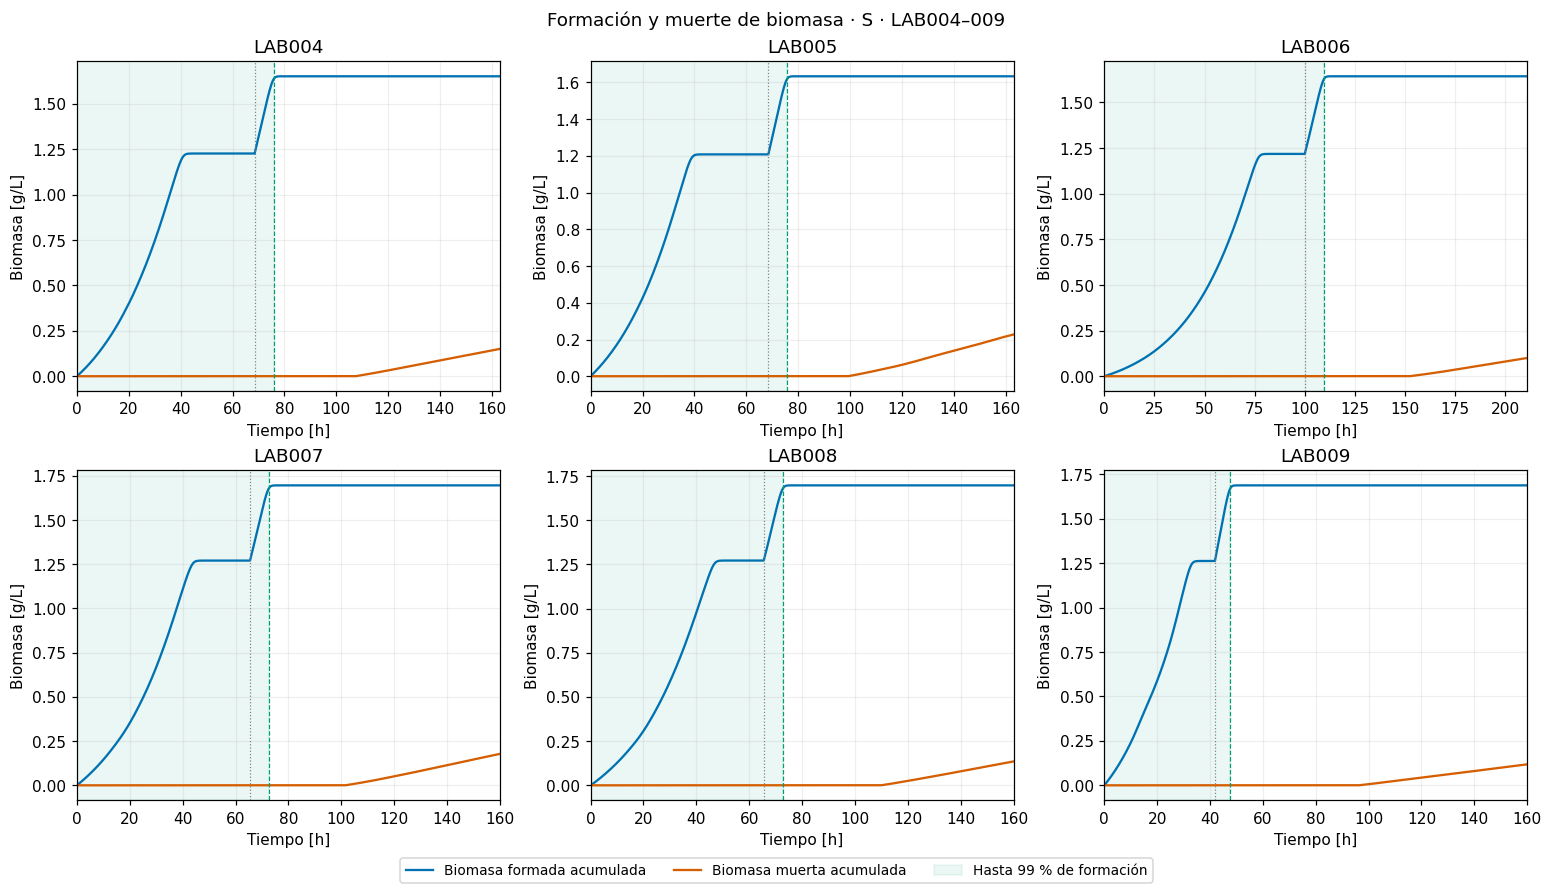

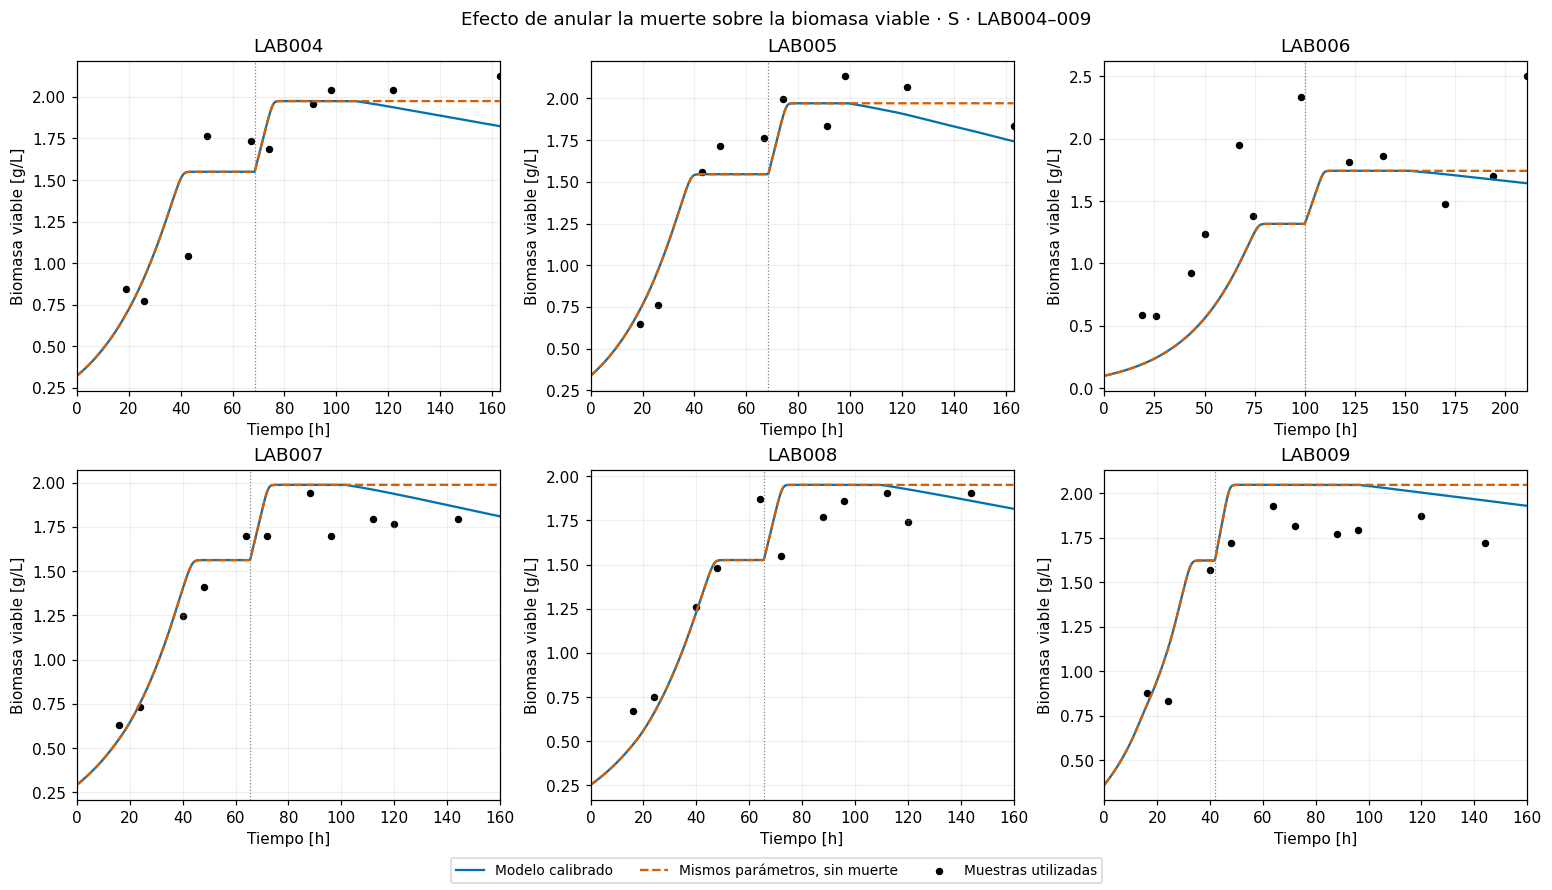

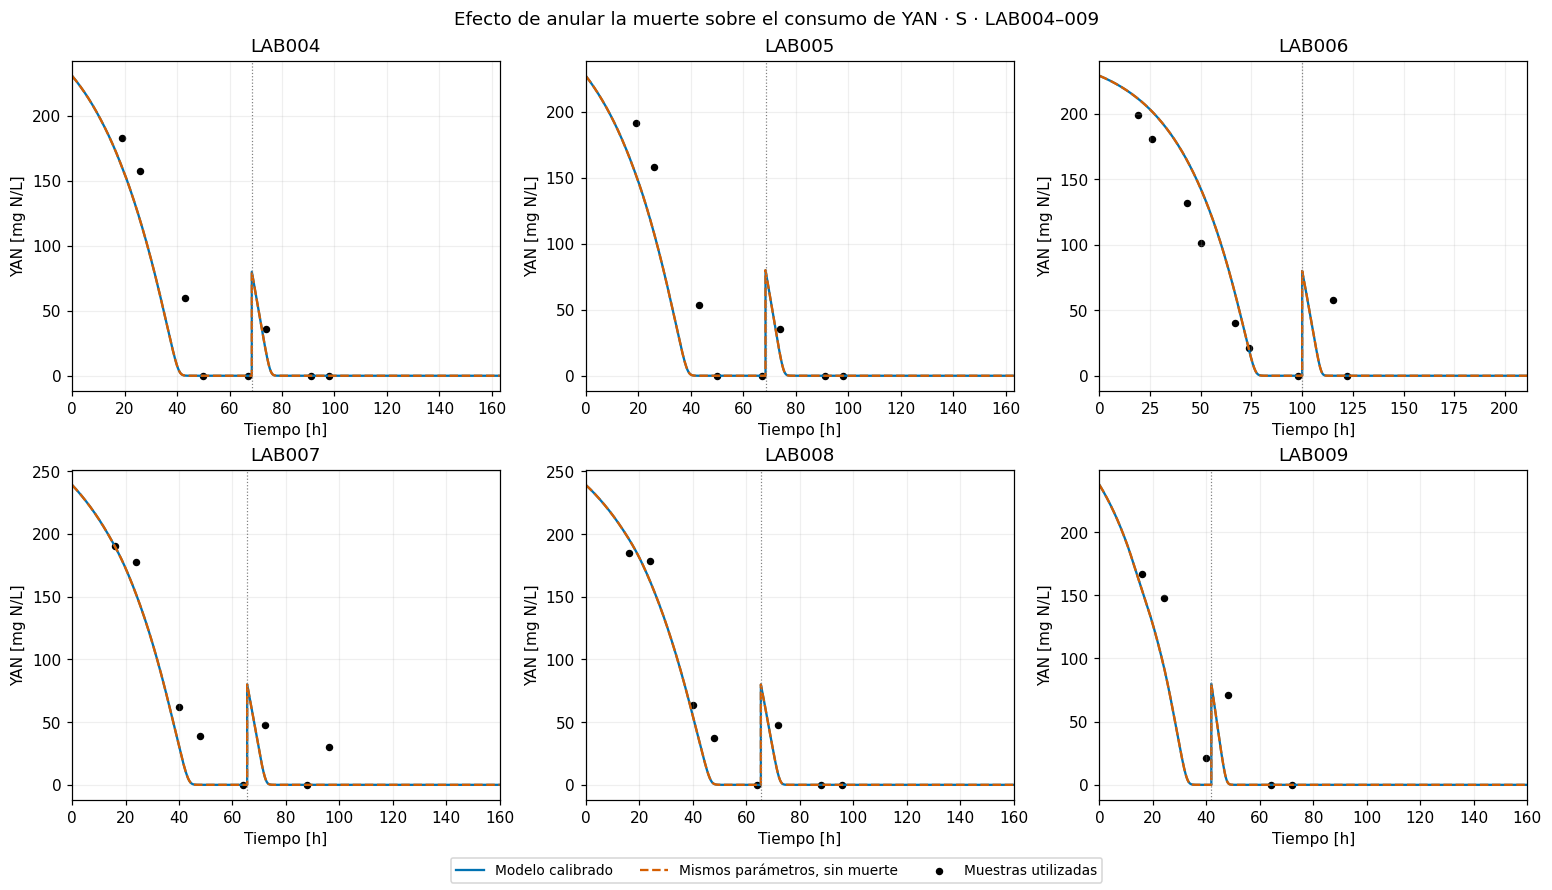

In [7]:
def mortality_plot_frame(frame):
    extra=[];times=[]
    for t,before,after in frame.attrs["jumps"]:
        extra.append(after);times.append(t)
    added=pd.DataFrame(extra,index=times,columns=frame.columns)
    return pd.concat([frame,added]).sort_index(kind="stable")

for variable in ("Acumuladas","X","N"):
    fig,axes=plt.subplots(2,3,figsize=(14,8),layout="constrained")
    for ax,(lab,batch) in zip(axes.flat,mortality_training.items()):
        frame=mortality_plot_frame(mortality_curves[lab]);counter=mortality_plot_frame(mortality_without_death[lab])
        t99=mortality_summary.at[lab,"99 % de formación [h]"]
        if variable=="Acumuladas":
            ax.plot(frame.index,frame.Formada,color="#0072B2",label="Biomasa formada acumulada")
            ax.plot(frame.index,frame.Muerta,color="#D55E00",label="Biomasa muerta acumulada")
            ax.axvspan(batch.time[0],t99,color="#009E73",alpha=.08,label="Hasta 99 % de formación")
            ax.axvline(t99,color="#009E73",ls="--",lw=.8)
            ax.set_ylabel("Biomasa [g/L]")
        else:
            factor=1000 if variable=="N" else 1
            ax.plot(frame.index,frame[variable]*factor,color="#0072B2",label="Modelo calibrado")
            ax.plot(counter.index,counter[variable]*factor,color="#D55E00",ls="--",label="Mismos parámetros, sin muerte")
            obs=batch.observations[variable];mask=np.isfinite(obs)&(batch.time>batch.time[0])
            ax.scatter(batch.time[mask],obs[mask]*factor,c="black",s=15,label="Muestras utilizadas")
            ax.set_ylabel("YAN [mg N/L]" if variable=="N" else "Biomasa viable [g/L]")
        for t,_ in batch.pulses["N"]:ax.axvline(t,color="gray",ls=":",lw=.8)
        ax.set(title=lab,xlabel="Tiempo [h]",xlim=(batch.time[0],batch.time[-1]));ax.grid(alpha=.2)
    handles,labels=axes.flat[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc="outside lower center",ncol=3,fontsize=9)
    title={"Acumuladas":"Formación y muerte de biomasa","X":"Efecto de anular la muerte sobre la biomasa viable","N":"Efecto de anular la muerte sobre el consumo de YAN"}[variable]
    fig.suptitle(title+f" · {mortality_model} · LAB004–009")
    plt.show()


## Resultado: alcance de la compensación entre mortalidad y rendimiento

En LAB004–009, la muerte integrada es cero hasta alcanzar el 99 % de la formación de biomasa. También es cero en las ventanas con YAN del modelo de al menos 1 mg N/L y 20 mg N/L. La mortalidad se activa posteriormente, cuando prácticamente todo el nitrógeno ya se ha consumido.

| Lote | 99 % de formación [h] | Primera muerte detectada [h] | Muerte hasta 99 % [g/L] | Muerte al final del lote [g/L] |
|---|---:|---:|---:|---:|
| LAB004 | 75,79 | 107,40 | 0,000000 | 0,151 |
| LAB005 | 75,67 | 99,20 | 0,000000 | 0,227 |
| LAB006 | 109,53 | 152,30 | 0,000000 | 0,100 |
| LAB007 | 72,62 | 101,60 | 0,000000 | 0,178 |
| LAB008 | 72,78 | 109,90 | 0,000000 | 0,135 |
| LAB009 | 47,67 | 96,20 | 0,000000 | 0,118 |

La primera muerte detectada se informa sobre una malla de como máximo 0,1 h; no es una medición experimental ni la localización exacta de la discontinuidad térmica. El horizonte final es el de cada lote original.

El caso con mortalidad anulada conserva las curvas de crecimiento durante el consumo apreciable de YAN y cambia la biomasa viable de la etapa posterior. La máxima diferencia de YAN entre ambos casos es inferior a 0,000001 mg N/L. Los balances integrados de biomasa y nitrógeno cierran con errores inferiores a 0,000002 g/L. La diferencia máxima entre el diagnóstico y el simulador original es 0.000351 g/L entre todos los estados; se conserva la química dentro de la tolerancia numérica declarada. La comprobación con paso de 0,05 h también satisface las tolerancias de estabilidad de la celda.

La comparación contable indica que, para adoptar un rendimiento de 10 g biomasa/g N manteniendo el nitrógeno consumido y la biomasa neta de la predicción actual hasta el 99 % de formación, haría falta perder aproximadamente **1.42–1.48 g/L** de biomasa en esa ventana. Eso equivale a cerca del **46.8 %** de la formación bruta hipotética; la ley actual predice **0 %** en esa misma ventana. Estos rendimientos hipotéticos sirven para dimensionar la diferencia, no para imponer valores de literatura como verdades del experimento.

**La mortalidad predicha actualmente no aporta la pérdida durante el crecimiento que sería necesaria para explicar un rendimiento bruto mucho mayor oculto tras una biomasa viable menor.** El rendimiento calibrado ya se aplica a la formación bruta de biomasa; no corresponde corregirlo sumando nuevamente la muerte. La pérdida tardía sí influye en las muestras finales de biomasa y puede influir indirectamente en un ajuste conjunto. Este contraste con parámetros fijos no cuantifica cuánto cambiaría el rendimiento al recalibrar otro modelo de mortalidad.

La ausencia de muerte temprana es una propiedad del modelo y sus trayectorias actuales, no una demostración de que no haya muerte real. La ley impone muerte cero por debajo del umbral térmico: aumentar solo su coeficiente de referencia no la activa mientras se conserve esa condición. Para investigar una compensación con mortalidad temprana habría que contrastar otra representación con datos de viabilidad o biomasa total y viable que la sustenten.

La revisión siguiente debe concentrarse en la relación observada entre incremento de biomasa y YAN consumido, la conversión de recuentos a masa, las condiciones iniciales, las nutriciones y el tratamiento de las lecturas de YAN. Este diagnóstico conserva todos los parámetros calibrados principales.
